# GeoCrashAI — Complete Analysis Notebook
**CSCE 878 · US Accidents (Feb 2016 – Mar 2023, 7.7M crashes)**

One notebook, end to end, every step with its output:

1. Setup & data loading
2. Data quality: types, missing values, duplicates
3. Cleaning & target creation
4. Exploratory data analysis (distributions, time, weather, scatter plots, correlations, road features, geography, statistical tests)
5. Outlier analysis & handling (IQR, z-score, impossible values, Isolation Forest, winsorizing)
6. Feature engineering & train/test split (temporal) + drift check
7. Preprocessing pipeline: imputation → clipping → **standardization** → one-hot encoding
8. **K-fold cross-validation** setup (stratified K-fold, K-fold, time-series split)
9. **Classification** — severe vs not severe (8 models, CV, test metrics, ROC/PR, calibration, threshold tuning, hyper-parameter search, class imbalance, random vs temporal split, 4-class severity, feature importance)
10. **Regression** — traffic-delay duration (9 models, CV, residual diagnostics, regularization path, learning curve, prediction intervals)
11. **Time series** — monthly national crash forecasting (decomposition, stationarity, ACF/PACF, 6 forecasters, rolling-origin CV)
12. **Clustering** — crash types (elbow, silhouette, 6 algorithms, PCA, t-SNE, dendrogram, profiles) + spatial hotspots (DBSCAN, Omaha)
13. Final summary of all results

Metric glossary is in section 8.

## 1. Setup

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (StratifiedKFold, KFold, TimeSeriesSplit, cross_validate, cross_val_predict,
                                     RandomizedSearchCV, train_test_split, validation_curve, learning_curve)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, GradientBoostingRegressor, IsolationForest)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, Birch, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn import metrics as M
from src.features import clean, temporal_split, ROAD_FLAGS, WEATHER_NUM

SEED = 878            # reproducibility
N = 150_000           # crashes analysed (random subset of the 10% national sample = 772,836 rows)
CV_N = 40_000         # rows used for K-fold cross-validation (keeps 8 models x 5 folds fast)
K = 5                 # folds
rng = np.random.default_rng(SEED)
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SEV_COLORS = {1: "#9bb8d3", 2: "#4a78b0", 3: "#e0912f", 4: "#c0392b"}
BLUE, RED, GREY = "#4a78b0", "#c0392b", "#999999"
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (9, 4)})
SUMMARY = []          # best result per task, collected as we go
print("ready")

ready


## 2. Load data & data quality
The 3 GB Kaggle CSV was streamed once by `src/ingest.py` into a uniform 10% national sample (seed 878). Here we take a random 150k-crash subset of it.

In [2]:
raw_full = pd.read_parquet("data/processed/national_sample.parquet")
print("national sample:", raw_full.shape)
raw = raw_full.sample(N, random_state=SEED).reset_index(drop=True)
print("working subset :", raw.shape)
raw.head()

national sample: (772836, 37)
working subset : (150000, 37)


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),City,County,State,Timezone,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-7593307,Source1,2,2018-04-13 16:56:32,2018-04-13 22:56:32,38.960995,-77.027972,0.422,Washington,District of Columbia,DC,US/Eastern,84.7,NaN,25.0,29.86,10.0,SSW,10.4,NaN,Clear,True,False,False,False,False,False,False,False,False,False,False,True,Day,Day,Day,Day
1,A-4217317,Source1,2,2022-11-14 11:18:48.000000000,2022-11-14 12:41:11.000000000,47.316256,-93.358205,0.584,Bovey,Itasca,MN,US/Central,25.0,19.0,80.0,28.84,1.0,SE,5.0,0.0,Light Snow,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-2366170,Source2,2,2019-01-29 18:41:06,2019-01-29 19:25:55,35.205559,-80.869469,0.000,Charlotte,Mecklenburg,NC,US/Eastern,41.0,36.4,76.0,29.91,10.0,NNW,6.9,NaN,Partly Cloudy,False,False,False,False,False,False,False,False,False,False,False,True,Night,Night,Day,Day
3,A-2828666,Source2,2,2018-05-16 11:28:36,2018-05-16 12:28:21,47.632298,-122.345955,0.000,Seattle,King,WA,US/Pacific,63.0,NaN,63.0,30.04,10.0,Variable,3.5,NaN,Mostly Cloudy,False,False,True,False,False,False,False,False,True,False,False,False,Day,Day,Day,Day
4,A-6538465,Source1,2,2021-01-17 03:44:39,2021-01-17 05:41:40,43.911441,-91.546615,3.175,Dakota,Winona,MN,US/Central,29.0,21.0,85.0,29.02,10.0,NNW,8.0,0.0,Cloudy,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night


In [3]:
print("column types:"); display(raw.dtypes.astype(str).value_counts().to_frame("columns"))
raw.describe(include="number").T.round(2)

column types:


,columns
str,14
bool,12
float64,10
int64,1


,count,mean,std,min,25%,50%,75%,max
Severity,150000.0,2.21,0.49,1.00,2.00,2.00,2.00,4.00
Start_Lat,150000.0,36.20,5.07,24.57,33.41,35.81,40.08,48.99
Start_Lng,150000.0,-94.74,17.39,-124.49,-117.22,-87.82,-80.37,-67.84
Distance(mi),150000.0,0.56,1.68,0.00,0.00,0.03,0.46,100.90
Temperature(F),146767.0,61.63,18.97,-77.80,49.00,64.00,76.00,170.60
Wind_Chill(F),111358.0,58.26,22.33,-52.60,43.00,62.00,75.00,140.00
Humidity(%),146575.0,64.82,22.87,1.00,48.00,67.00,84.00,100.00
Pressure(in),147242.0,29.53,1.01,19.53,29.36,29.85,30.03,30.92
Visibility(mi),146540.0,9.08,2.66,0.00,10.00,10.00,10.00,80.00
Wind_Speed(mph),138815.0,7.67,5.26,0.00,4.60,7.00,10.40,81.00


,% missing
Precipitation(in),28.25
Wind_Chill(F),25.76
Wind_Speed(mph),7.46
Wind_Direction,2.33
Visibility(mi),2.31
Humidity(%),2.28
Weather_Condition,2.26
Temperature(F),2.16
Pressure(in),1.84
Nautical_Twilight,0.30


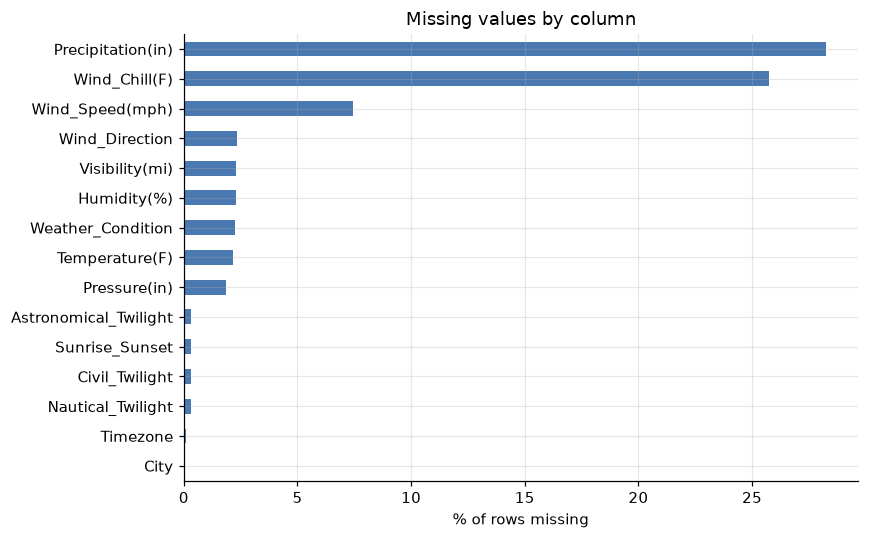

In [4]:
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
display(miss.round(2).to_frame("% missing"))
ax = miss.sort_values().plot.barh(color=BLUE, figsize=(8, 5))
ax.set(title="Missing values by column", xlabel="% of rows missing"); plt.tight_layout(); plt.show()

In [5]:
dup_id = raw.ID.duplicated().sum()
dup_evt = raw.duplicated(subset=["Start_Time", "Start_Lat", "Start_Lng"]).sum()
print(f"duplicate IDs: {dup_id}   duplicate (time, location) events: {dup_evt}")
print("categorical cardinality:"); display(raw[["Source", "State", "City", "Weather_Condition", "Wind_Direction", "Sunrise_Sunset"]].nunique().to_frame("unique values"))

duplicate IDs: 0   duplicate (time, location) events: 213
categorical cardinality:


,unique values
Source,3
State,49
City,7203
Weather_Condition,86
Wind_Direction,24
Sunrise_Sunset,2


## 3. Cleaning & targets
`src.features.clean()`:
- parses times, **duration = End − Start** (kept 1 min … 7 days; longer are roadworks logged as crashes),
- removes invalid coordinates / severities,
- derives `hour, dow, month, year, is_weekend, is_rush_hour, is_night`,
- collapses ~140 weather strings into 8 groups,
- targets: `Severity` (1–4), `is_severe` (Severity ≥ 3), `log_duration = log(1 + minutes)`.

`Distance(mi)` is **dropped from modelling**: it is the length of road affected, known only after the event (target leakage).

In [6]:
dedup = raw.drop_duplicates(subset=["Start_Time", "Start_Lat", "Start_Lng"])
df = clean(dedup)
steps = pd.DataFrame({"rows": [len(raw), len(dedup), len(df)]},
                     index=["loaded", "after removing duplicate events", "after cleaning (valid time/duration/coords)"])
steps["dropped"] = -steps.rows.diff().fillna(0).astype(int)
display(steps)
df[["Start_Time", "End_Time", "duration_min", "log_duration", "Severity", "is_severe", "hour", "dow", "weather_group"]].head()

,rows,dropped
loaded,150000,0
after removing duplicate events,149787,213
after cleaning (valid time/duration/coords),149653,134


,Start_Time,End_Time,duration_min,log_duration,Severity,is_severe,hour,dow,weather_group
0,2016-02-08 06:15:39,2016-02-08 12:15:39,360.0,5.888878,2,0,6,0,cloudy
1,2016-02-08 09:35:35,2016-02-08 10:05:35,30.0,3.433987,2,0,9,0,cloudy
2,2016-02-08 14:56:57,2016-02-08 15:41:57,45.0,3.828641,2,0,14,0,cloudy
3,2016-02-09 07:44:49,2016-02-09 13:44:49,360.0,5.888878,3,1,7,1,snow
4,2016-02-09 07:48:40,2016-02-09 13:48:40,360.0,5.888878,3,1,7,1,snow


## 4. Exploratory data analysis
### 4.1 Targets

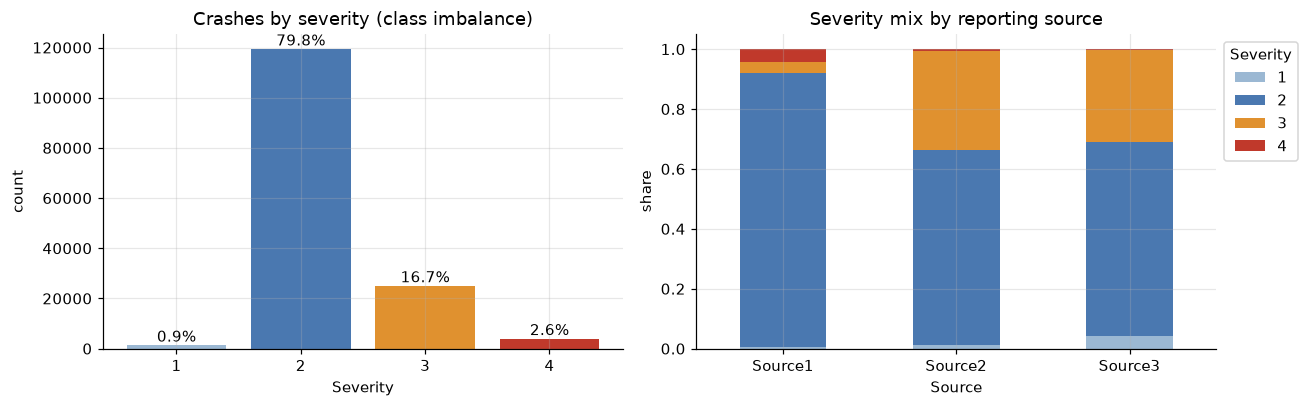

severe (3-4) share: 19.4%  -> imbalanced binary target


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
c = df.Severity.value_counts().sort_index()
ax[0].bar(c.index.astype(str), c.values, color=[SEV_COLORS[s] for s in c.index])
for i, v in enumerate(c.values):
    ax[0].text(i, v, f"{v / c.sum():.1%}", ha="center", va="bottom")
ax[0].set(title="Crashes by severity (class imbalance)", xlabel="Severity", ylabel="count")
ct = pd.crosstab(df.Source, df.Severity, normalize="index")
ct.plot.bar(stacked=True, ax=ax[1], color=[SEV_COLORS[s] for s in ct.columns], rot=0)
ax[1].set(title="Severity mix by reporting source", ylabel="share"); ax[1].legend(title="Severity", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
print(f"severe (3-4) share: {df.is_severe.mean():.1%}  -> imbalanced binary target")

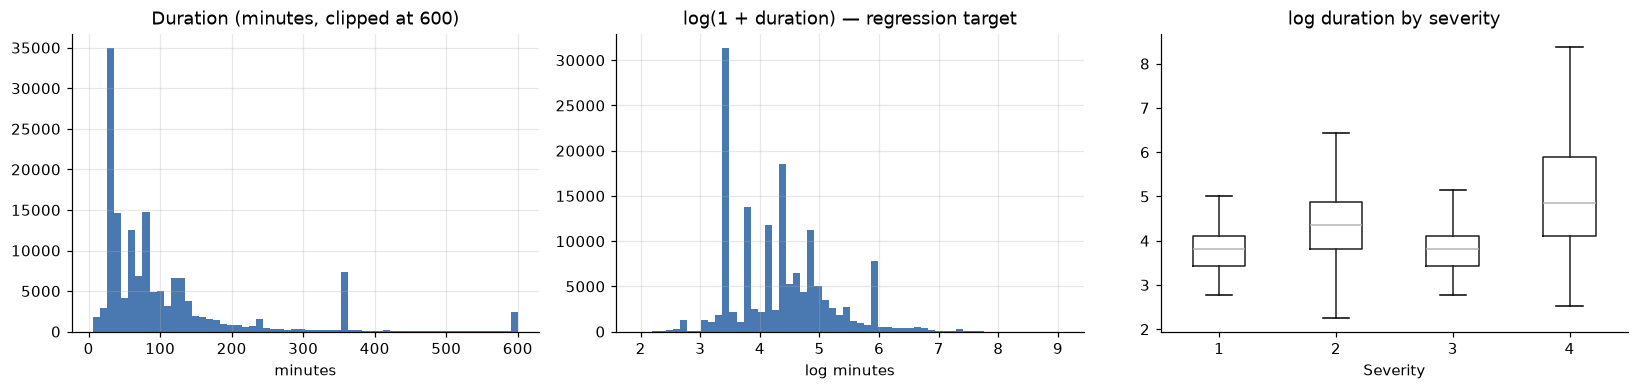

skewness raw: 12.63   after log: 0.70


,count,mean,std,min,10%,25%,50%,75%,90%,max
Severity,,,,,,,,,,
1,1335.0,44.3,28.6,15.0,15.0,29.6,44.5,59.4,65.0,360.9
2,119359.0,121.3,180.4,6.0,29.6,44.4,77.5,128.9,242.0,7391.1
3,25000.0,68.3,94.5,15.0,29.3,29.6,44.4,60.0,119.4,6067.7
4,3959.0,218.9,391.7,11.4,29.3,60.0,127.8,360.0,360.0,8712.0


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(df.duration_min.clip(upper=600), bins=60, color=BLUE); ax[0].set(title="Duration (minutes, clipped at 600)", xlabel="minutes")
ax[1].hist(df.log_duration, bins=60, color=BLUE); ax[1].set(title="log(1 + duration) — regression target", xlabel="log minutes")
df.boxplot(column="log_duration", by="Severity", ax=ax[2], grid=False, showfliers=False); ax[2].set(title="log duration by severity", xlabel="Severity"); plt.suptitle("")
plt.tight_layout(); plt.show()
print(f"skewness raw: {df.duration_min.skew():.2f}   after log: {df.log_duration.skew():.2f}")
display(df.groupby("Severity").duration_min.describe(percentiles=[.1, .25, .5, .75, .9]).round(1))

### 4.2 When do crashes happen?

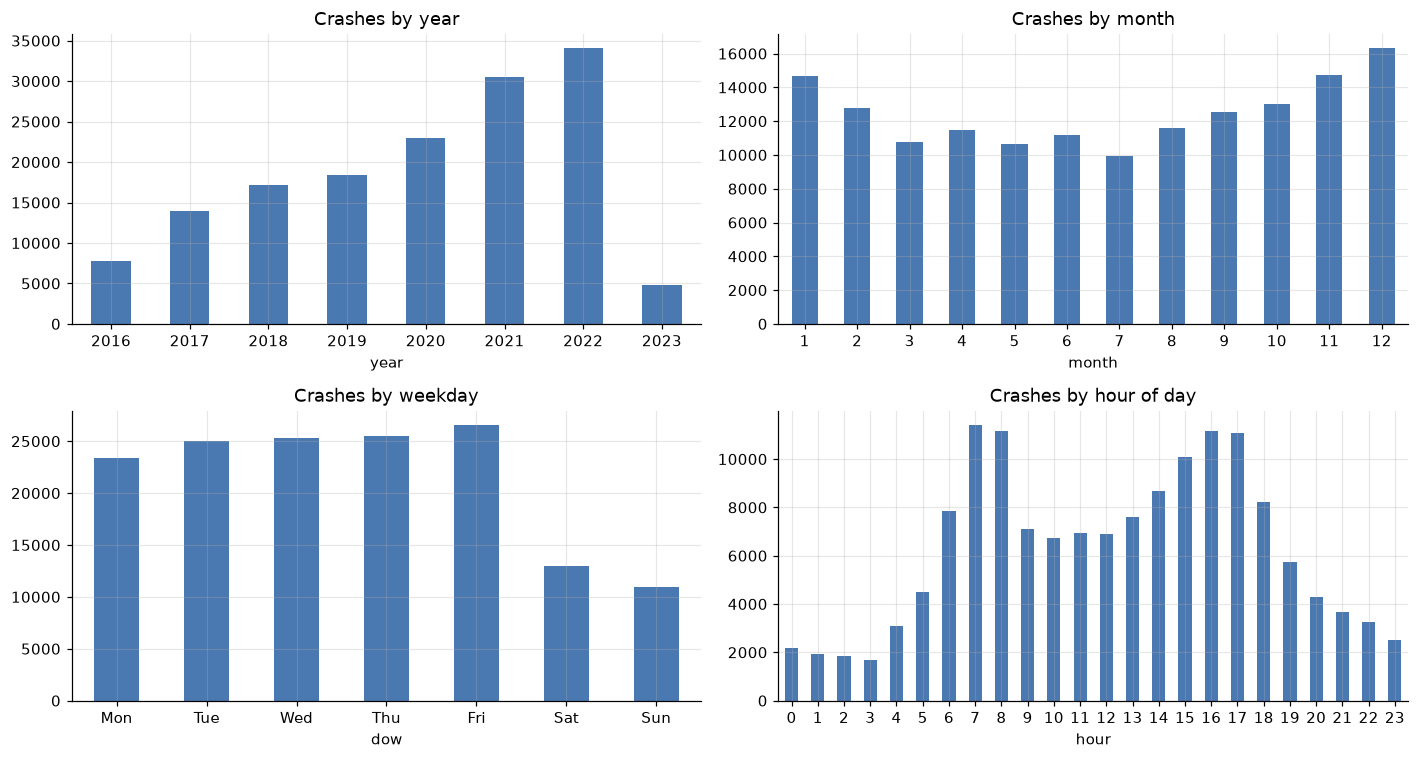

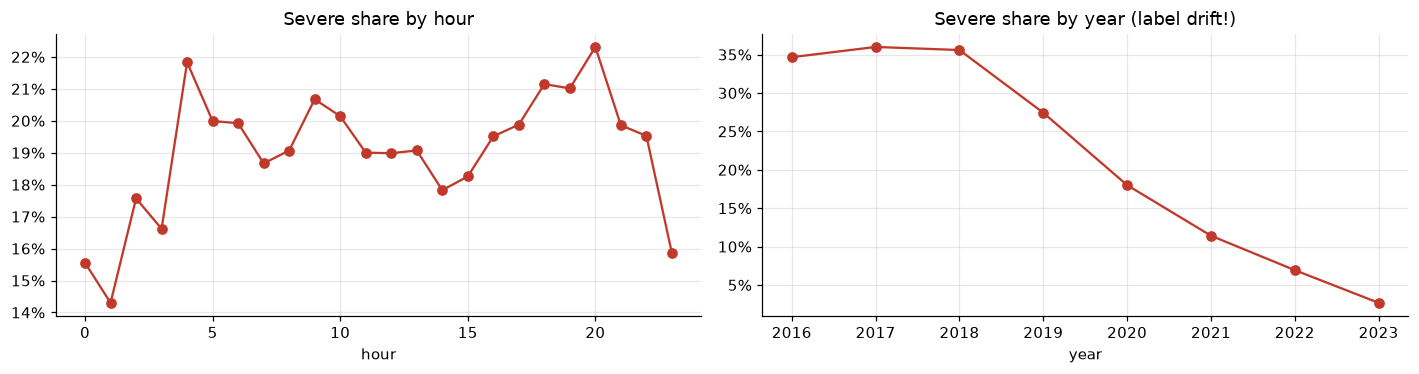

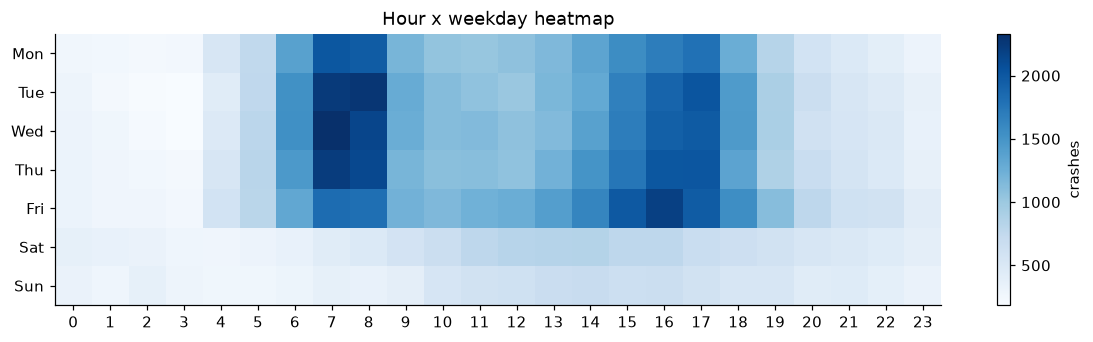

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
df.year.value_counts().sort_index().plot.bar(ax=ax[0, 0], color=BLUE, rot=0, title="Crashes by year")
df.month.value_counts().sort_index().plot.bar(ax=ax[0, 1], color=BLUE, rot=0, title="Crashes by month")
df.dow.value_counts().sort_index().rename(index=dict(enumerate(DOW))).plot.bar(ax=ax[1, 0], color=BLUE, rot=0, title="Crashes by weekday")
df.hour.value_counts().sort_index().plot.bar(ax=ax[1, 1], color=BLUE, rot=0, title="Crashes by hour of day")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
df.groupby("hour").is_severe.mean().plot(ax=ax[0], marker="o", color=RED, title="Severe share by hour")
df.groupby("year").is_severe.mean().plot(ax=ax[1], marker="o", color=RED, title="Severe share by year (label drift!)")
for a in ax: a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

hm = pd.crosstab(df.dow, df.hour)
plt.figure(figsize=(13, 3.2)); plt.imshow(hm, aspect="auto", cmap="Blues")
plt.yticks(range(7), DOW); plt.xticks(range(24)); plt.colorbar(label="crashes"); plt.title("Hour x weekday heatmap"); plt.grid(False); plt.show()

### 4.3 Weather

,n,severe_rate,median_duration
weather_group,,,
clear,66192,0.170,75.767
cloudy,61107,0.215,61.300
rain,9947,0.227,62.900
fog,3989,0.149,76.500
unknown,3381,0.214,76.500
snow,3354,0.191,80.842
thunder,1608,0.203,75.467
other,75,0.173,95.950


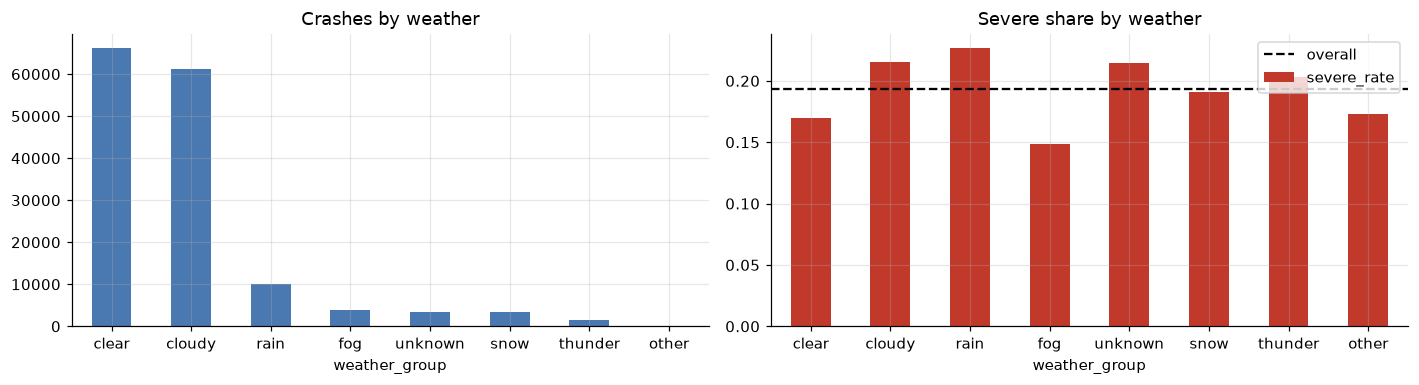

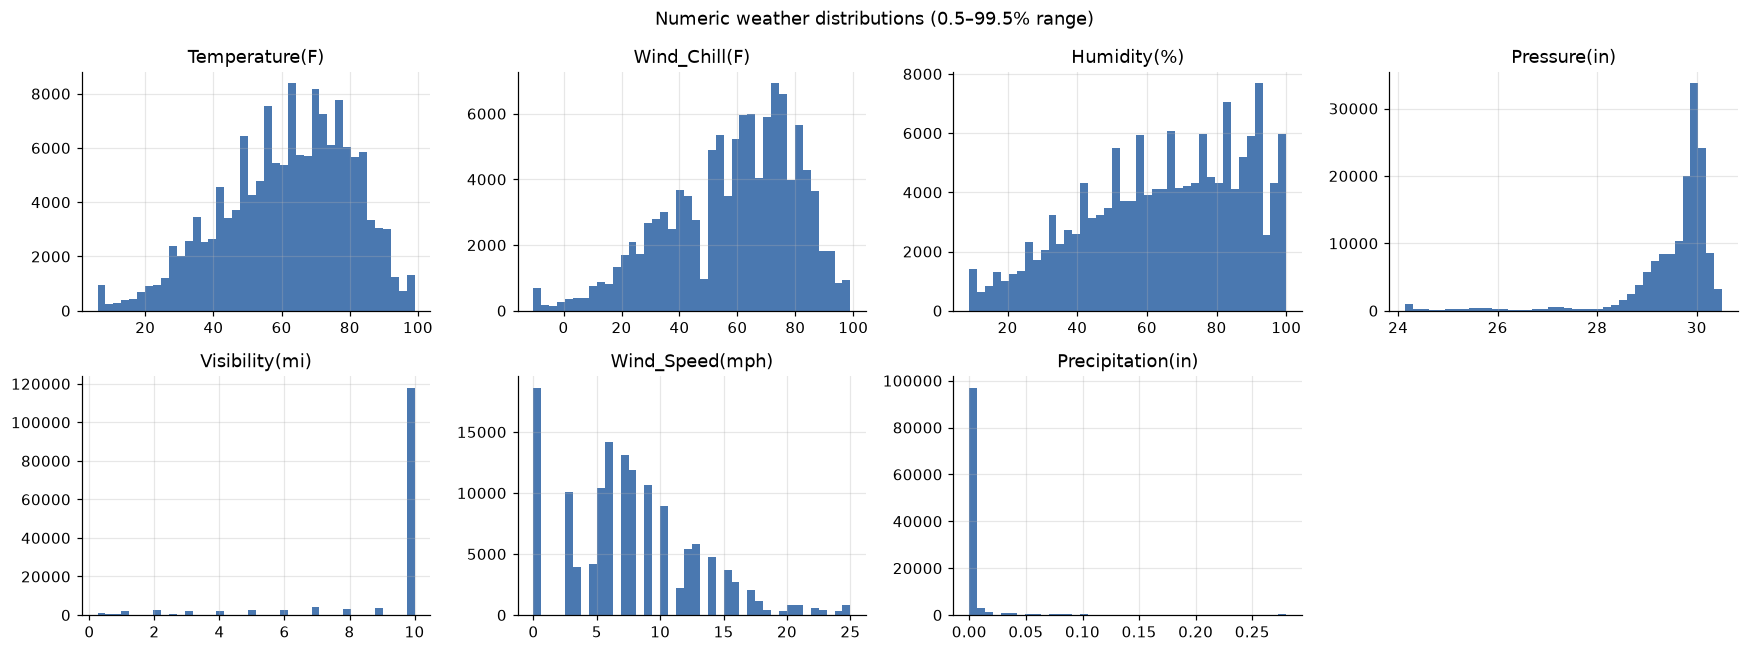

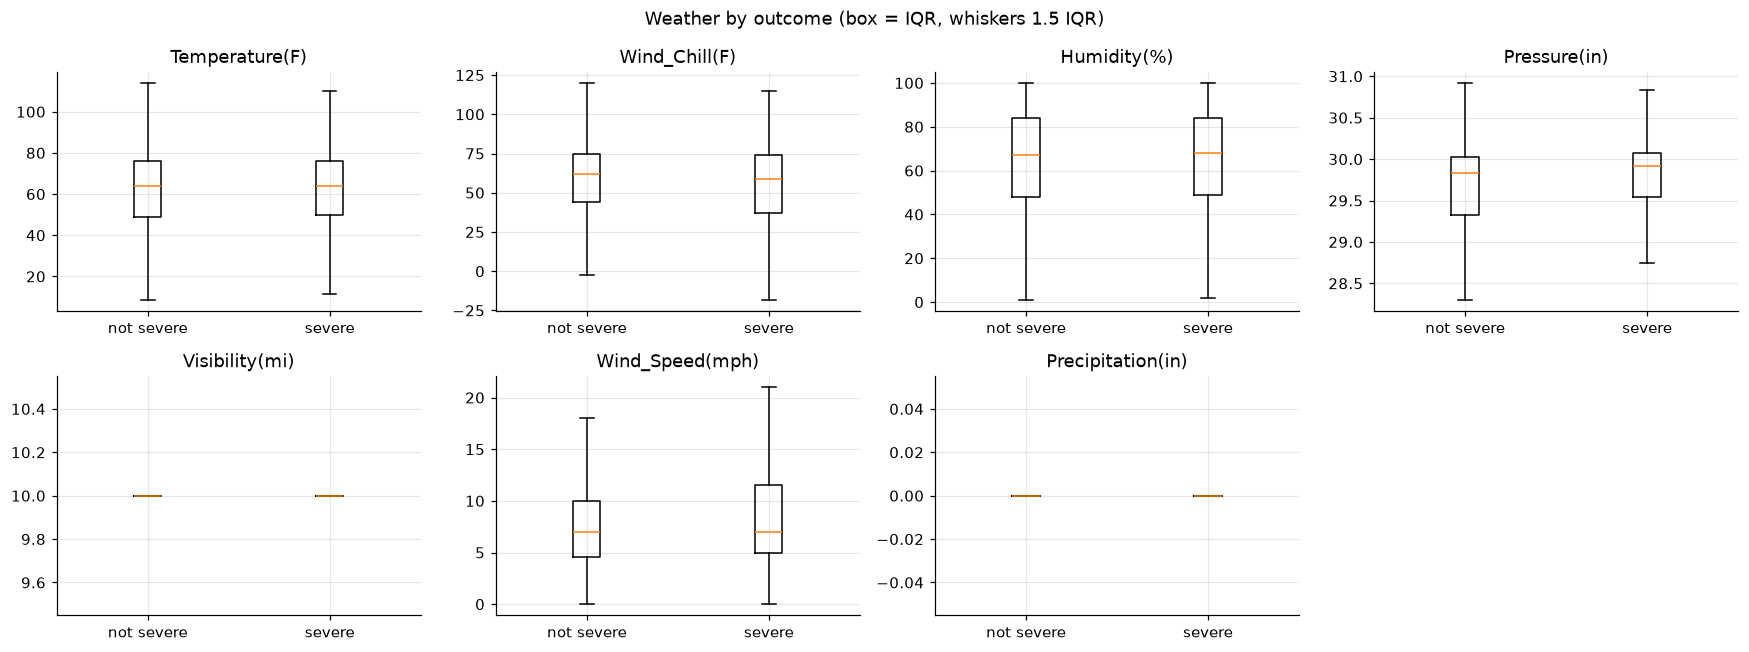

In [10]:
g = (df.groupby("weather_group", observed=True)
       .agg(n=("is_severe", "size"), severe_rate=("is_severe", "mean"), median_duration=("duration_min", "median"))
       .sort_values("n", ascending=False))
display(g.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
g.n.plot.bar(ax=ax[0], color=BLUE, rot=0, title="Crashes by weather")
g.severe_rate.plot.bar(ax=ax[1], color=RED, rot=0, title="Severe share by weather")
ax[1].axhline(df.is_severe.mean(), ls="--", color="k", label="overall"); ax[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for a, col in zip(axes.flat, WEATHER_NUM):
    s = df[col].dropna(); lo, hi = s.quantile([0.005, 0.995])
    a.hist(s.clip(lo, hi), bins=40, color=BLUE); a.set_title(col)
axes.flat[-1].axis("off"); plt.suptitle("Numeric weather distributions (0.5–99.5% range)"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for a, col in zip(axes.flat, WEATHER_NUM):
    parts = [df.loc[df.is_severe == k, col].dropna() for k in (0, 1)]
    a.boxplot(parts, tick_labels=["not severe", "severe"], showfliers=False); a.set_title(col)
axes.flat[-1].axis("off"); plt.suptitle("Weather by outcome (box = IQR, whiskers 1.5 IQR)"); plt.tight_layout(); plt.show()

### 4.4 Scatter plots (4,000 random crashes, coloured by severity)

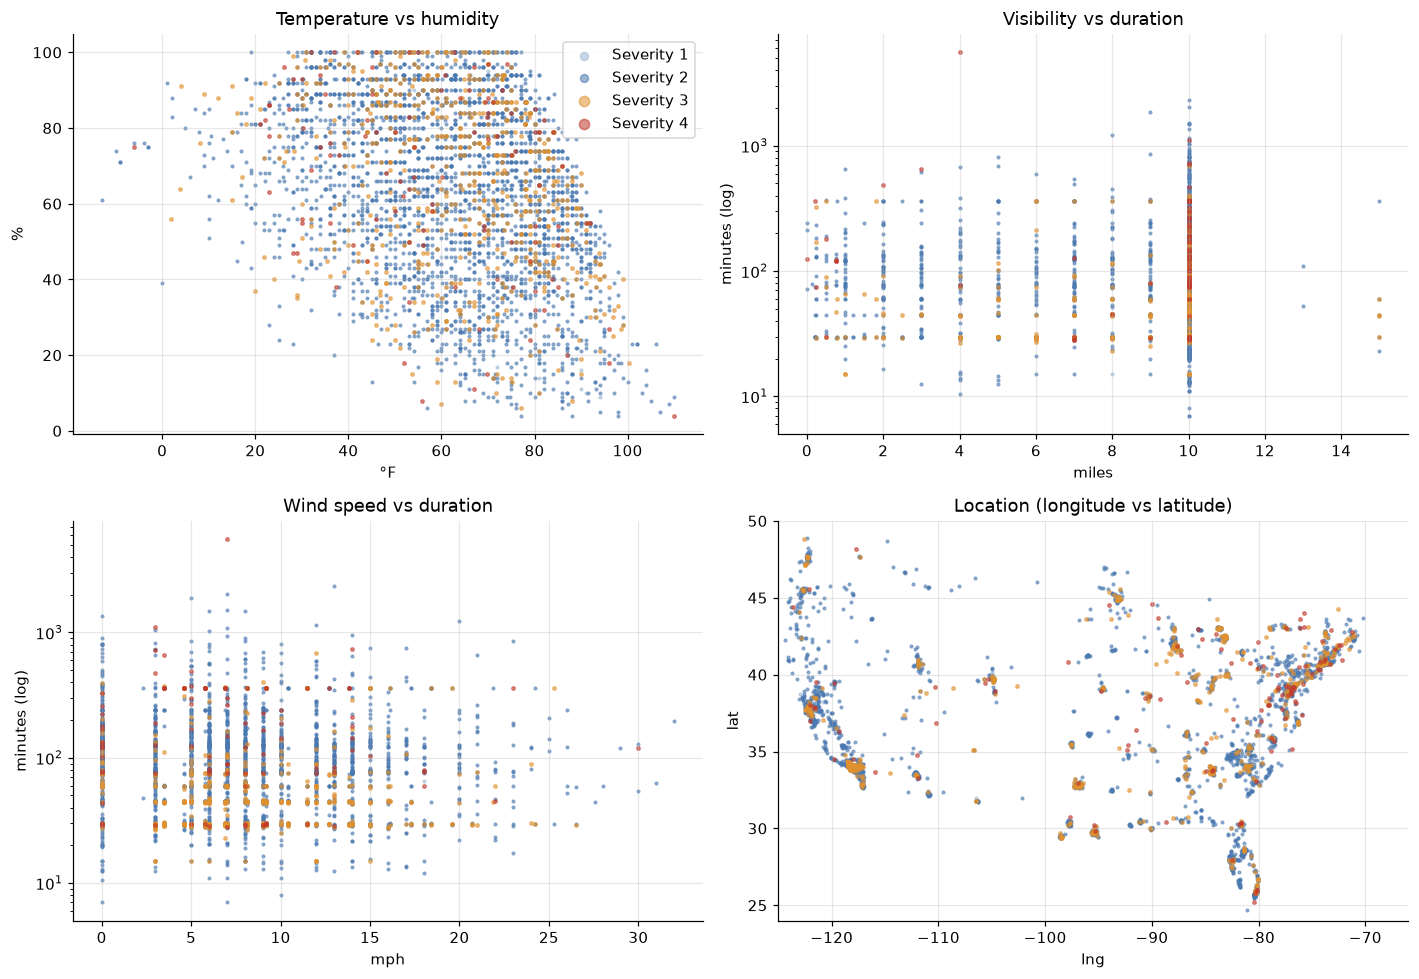

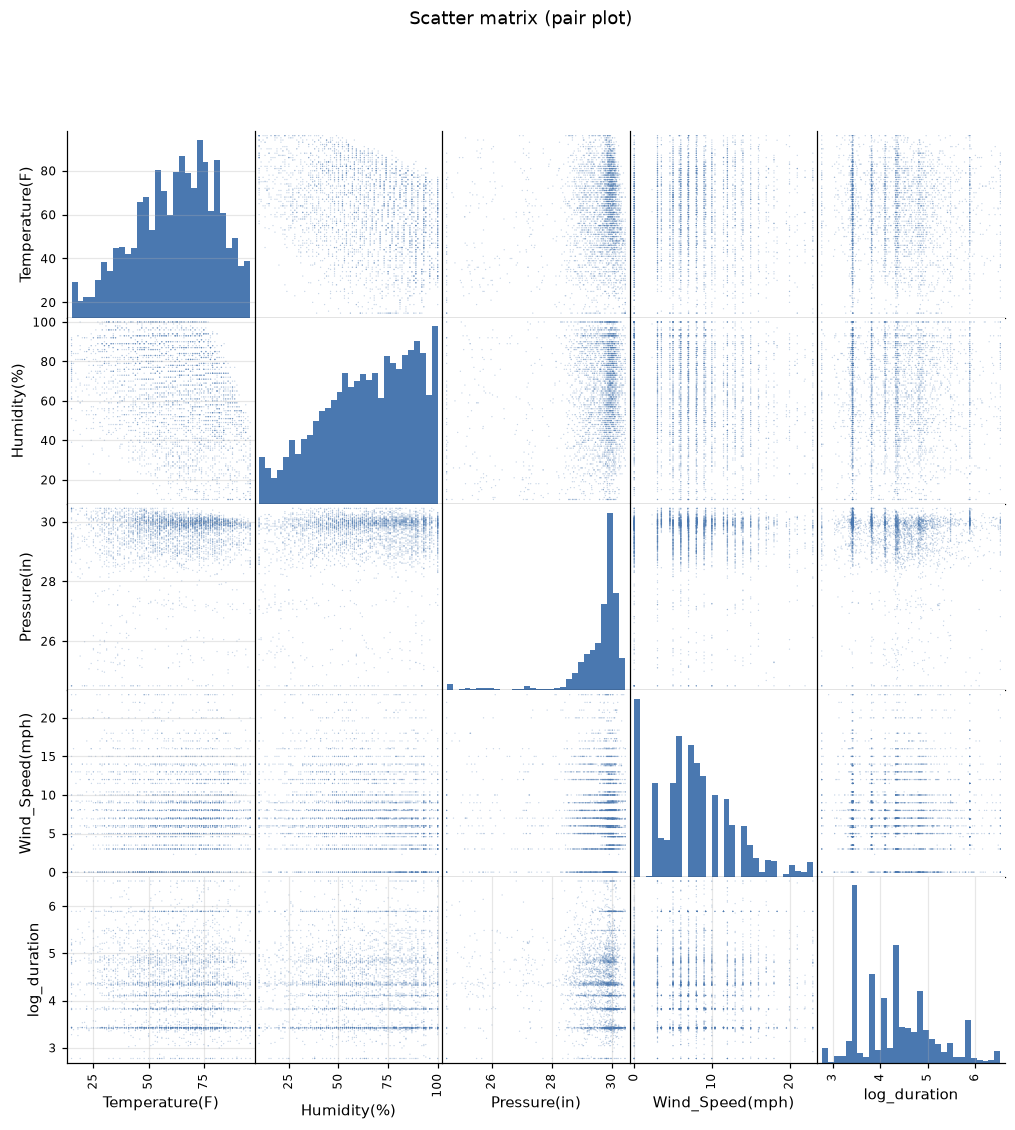

In [11]:
s = df.sample(4000, random_state=SEED)
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for sev in (1, 2, 3, 4):
    m = s.Severity == sev
    kw = dict(s=5 if sev >= 3 else 3, alpha=0.55, color=SEV_COLORS[sev], label=f"Severity {sev}")
    ax[0, 0].scatter(s.loc[m, "Temperature(F)"], s.loc[m, "Humidity(%)"], **kw)
    ax[0, 1].scatter(s.loc[m, "Visibility(mi)"].clip(upper=15), s.loc[m, "duration_min"], **kw)
    ax[1, 0].scatter(s.loc[m, "Wind_Speed(mph)"].clip(upper=50), s.loc[m, "duration_min"], **kw)
    ax[1, 1].scatter(s.loc[m, "Start_Lng"], s.loc[m, "Start_Lat"], **kw)
ax[0, 0].set(title="Temperature vs humidity", xlabel="°F", ylabel="%")
ax[0, 1].set(title="Visibility vs duration", xlabel="miles", ylabel="minutes (log)", yscale="log")
ax[1, 0].set(title="Wind speed vs duration", xlabel="mph", ylabel="minutes (log)", yscale="log")
ax[1, 1].set(title="Location (longitude vs latitude)", xlabel="lng", ylabel="lat", xlim=(-125, -66), ylim=(24, 50))
ax[0, 0].legend(markerscale=3); plt.tight_layout(); plt.show()

pd.plotting.scatter_matrix(s[["Temperature(F)", "Humidity(%)", "Pressure(in)", "Wind_Speed(mph)", "log_duration"]].clip(
    lower=s[["Temperature(F)", "Humidity(%)", "Pressure(in)", "Wind_Speed(mph)", "log_duration"]].quantile(0.01),
    upper=s[["Temperature(F)", "Humidity(%)", "Pressure(in)", "Wind_Speed(mph)", "log_duration"]].quantile(0.99), axis=1),
    figsize=(11, 11), s=3, alpha=0.3, color=BLUE, hist_kwds={"color": BLUE, "bins": 30})
plt.suptitle("Scatter matrix (pair plot)"); plt.show()

### 4.5 Correlations

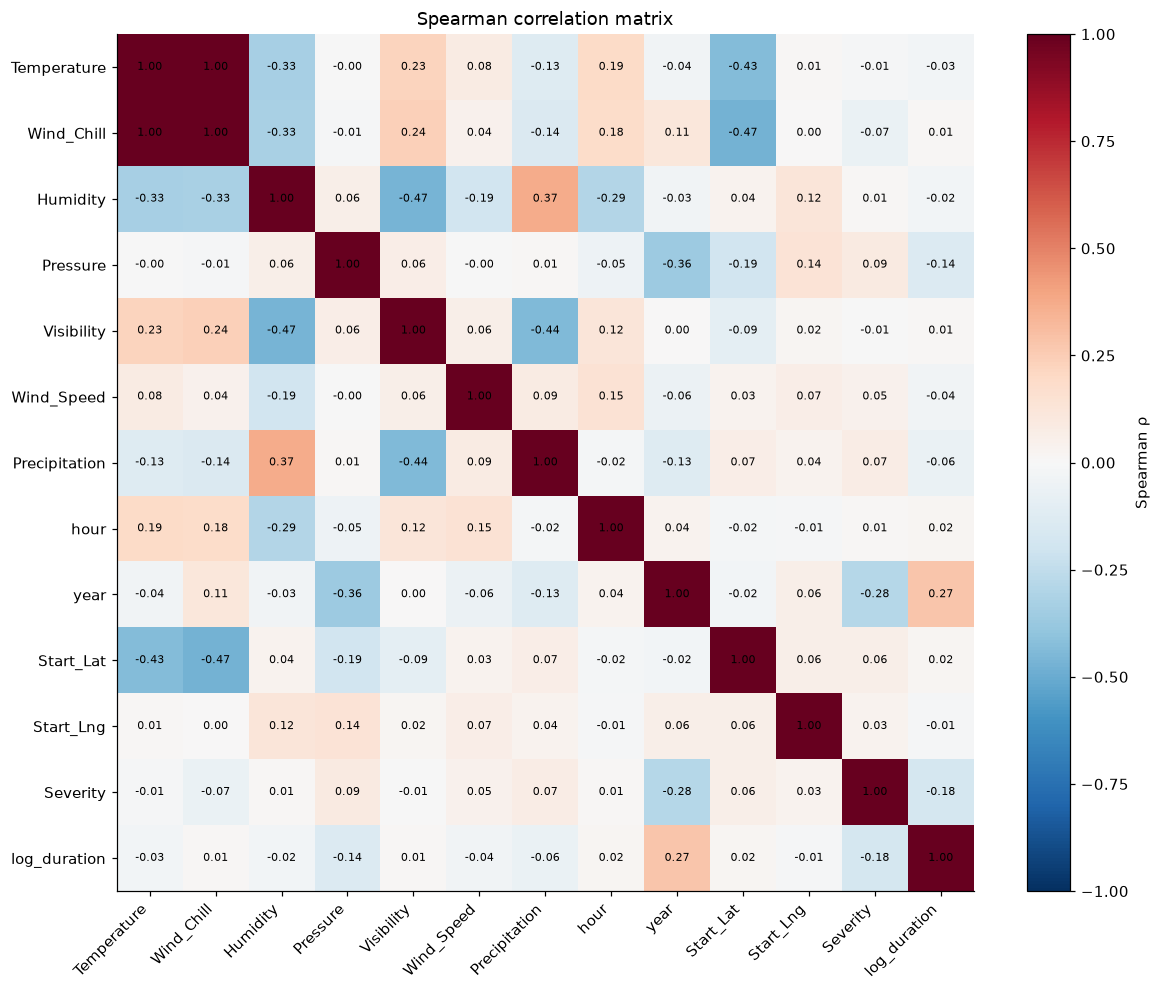

Strongest correlations with Severity / log_duration:


,Severity,log_duration
year,-0.282,0.274
Pressure(in),0.093,-0.138
Precipitation(in),0.073,-0.063
Wind_Chill(F),-0.066,0.011
Start_Lat,0.061,0.018
Wind_Speed(mph),0.047,-0.039
Start_Lng,0.032,-0.009
hour,0.014,0.018
Humidity(%),0.013,-0.024
Temperature(F),-0.012,-0.025


In [12]:
cols = WEATHER_NUM + ["hour", "year", "Start_Lat", "Start_Lng", "Severity", "log_duration"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), [c.split("(")[0] for c in cols], rotation=45, ha="right"); ax.set_yticks(range(len(cols)), [c.split("(")[0] for c in cols])
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Spearman ρ"); ax.set_title("Spearman correlation matrix"); ax.grid(False); plt.tight_layout(); plt.show()
print("Strongest correlations with Severity / log_duration:")
display(corr[["Severity", "log_duration"]].drop(["Severity", "log_duration"]).round(3).sort_values("Severity", key=abs, ascending=False))

### 4.6 Road features & geography

,share_of_crashes,severe_with,severe_without,lift
Traffic_Signal,0.148,0.092,0.211,0.438
Crossing,0.113,0.068,0.209,0.327
Junction,0.073,0.264,0.188,1.406
Stop,0.028,0.056,0.197,0.286
Station,0.026,0.070,0.197,0.355
Amenity,0.013,0.062,0.195,0.319
Railway,0.009,0.151,0.194,0.778
Give_Way,0.005,0.164,0.194,0.846
No_Exit,0.003,0.101,0.194,0.520
Traffic_Calming,0.001,0.138,0.194,0.714


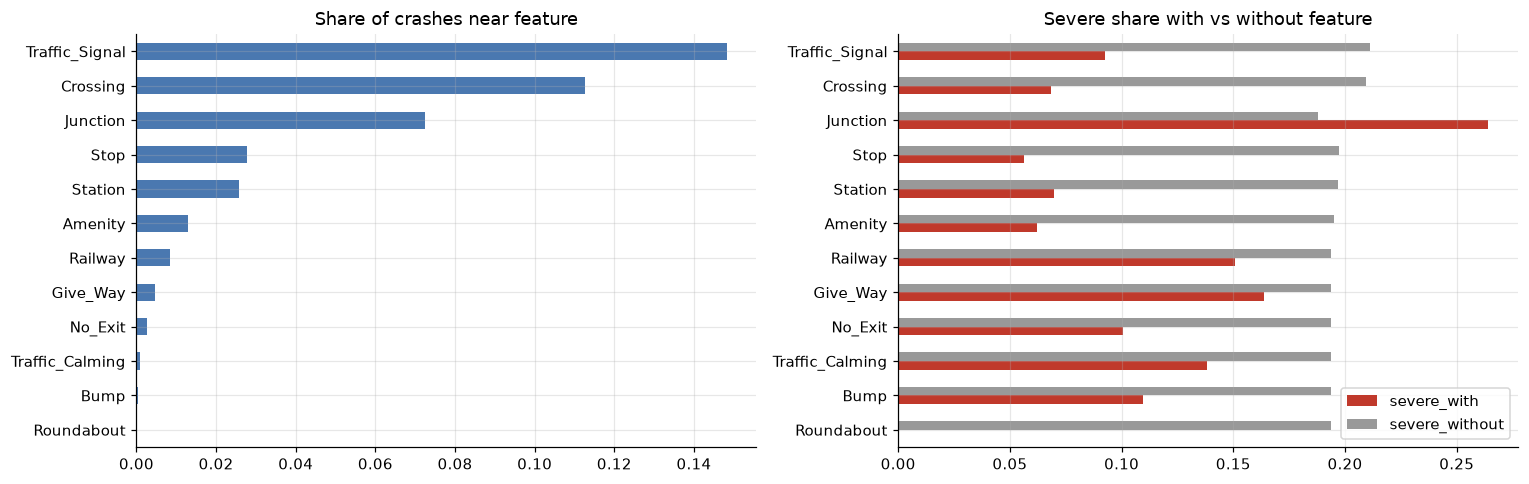

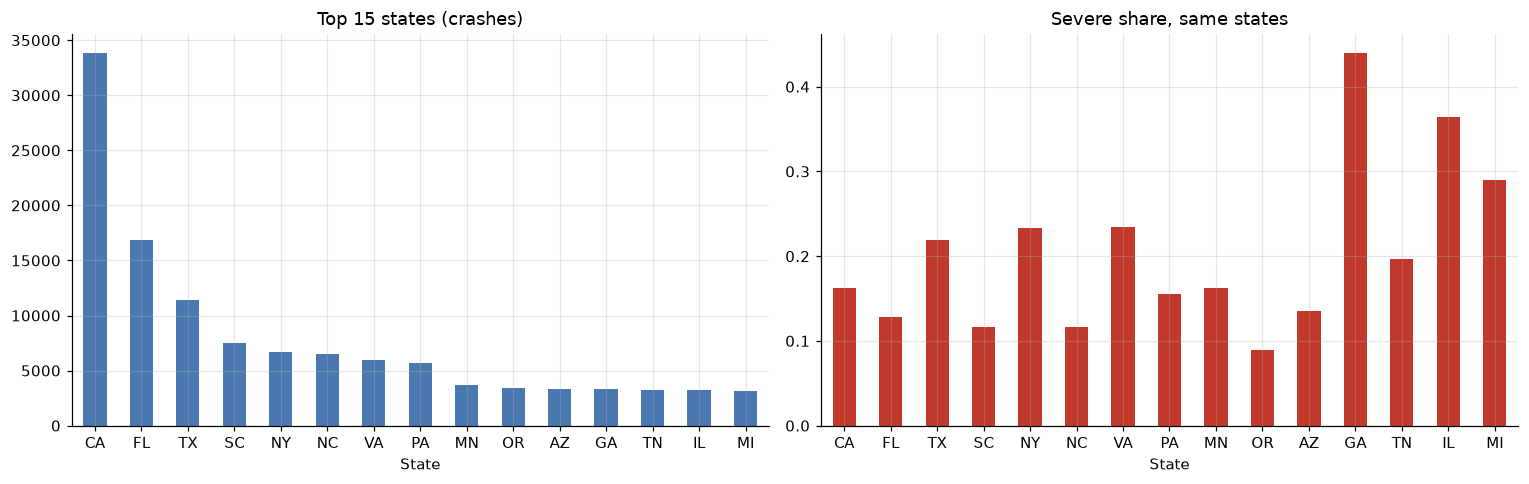

In [13]:
rf = pd.DataFrame({"share_of_crashes": df[ROAD_FLAGS].mean(),
                   "severe_with": [df.loc[df[f] == 1, "is_severe"].mean() for f in ROAD_FLAGS],
                   "severe_without": [df.loc[df[f] == 0, "is_severe"].mean() for f in ROAD_FLAGS]}, index=ROAD_FLAGS)
rf["lift"] = rf.severe_with / rf.severe_without
display(rf.sort_values("share_of_crashes", ascending=False).round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
rf.share_of_crashes.sort_values().plot.barh(ax=ax[0], color=BLUE, title="Share of crashes near feature")
rf.sort_values("share_of_crashes")[["severe_with", "severe_without"]].plot.barh(ax=ax[1], color=[RED, GREY], title="Severe share with vs without feature")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
st = df.groupby("State").agg(n=("is_severe", "size"), severe=("is_severe", "mean")).sort_values("n", ascending=False).head(15)
st.n.plot.bar(ax=ax[0], color=BLUE, rot=0, title="Top 15 states (crashes)")
st.severe.plot.bar(ax=ax[1], color=RED, rot=0, title="Severe share, same states")
plt.tight_layout(); plt.show()

### 4.7 Statistical tests
With 150k rows almost everything is 'significant', so effect sizes (Cramér's V, rank-biserial r) matter more than p-values.

In [14]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
rows = []
for col in ["weather_group", "Source", "is_night", "Junction", "Traffic_Signal", "Crossing"]:
    ct = pd.crosstab(df[col], df.is_severe); chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({"test": f"chi-square: {col} vs is_severe", "statistic": chi2, "p_value": p, "effect": f"Cramér's V = {cramers_v(ct):.3f}"})
for col in ["Visibility(mi)", "Temperature(F)", "Wind_Speed(mph)"]:
    a, b = df.loc[df.is_severe == 1, col].dropna(), df.loc[df.is_severe == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b)
    rows.append({"test": f"Mann-Whitney: {col} severe vs not", "statistic": u, "p_value": p, "effect": f"rank-biserial r = {1 - 2 * u / (len(a) * len(b)):.3f}"})
h, p = stats.kruskal(*[g.log_duration for _, g in df.groupby("Severity")])
rows.append({"test": "Kruskal-Wallis: log_duration across severities", "statistic": h, "p_value": p, "effect": f"ε² = {h / (len(df) - 1):.3f}"})
pd.DataFrame(rows).set_index("test")

,statistic,p_value,effect
test,,,
chi-square: weather_group vs is_severe,5.587746e+02,1.825892e-116,Cramér's V = 0.061
chi-square: Source vs is_severe,1.545901e+04,0.000000e+00,Cramér's V = 0.321
chi-square: is_night vs is_severe,1.010652e+01,1.477455e-03,Cramér's V = 0.008
chi-square: Junction vs is_severe,3.744934e+02,1.967199e-83,Cramér's V = 0.050
chi-square: Traffic_Signal vs is_severe,1.704521e+03,0.000000e+00,Cramér's V = 0.107
chi-square: Crossing vs is_severe,1.903419e+03,0.000000e+00,Cramér's V = 0.113
Mann-Whitney: Visibility(mi) severe vs not,1.658236e+09,1.316696e-01,rank-biserial r = 0.004
Mann-Whitney: Temperature(F) severe vs not,1.673847e+09,8.000866e-01,rank-biserial r = -0.001
Mann-Whitney: Wind_Speed(mph) severe vs not,1.547937e+09,1.074654e-72,rank-biserial r = -0.072


## 5. Outliers
Three views: per-variable **IQR rule** (outside Q1 − 1.5·IQR … Q3 + 1.5·IQR), **z-score > 3**, and a multivariate **Isolation Forest**. Then the handling decision.

,n,iqr_low,iqr_high,iqr_%,z>3_%,lower_fence,upper_fence,min,p1,median,p99,max
variable,,,,,,,,,,,,
Temperature(F),146428,941,4,0.65,0.45,8.50,116.50,-77.80,13.00,64.00,96.00,170.60
Wind_Chill(F),111033,825,1,0.74,0.57,-5.00,123.00,-52.60,-1.30,62.00,96.00,140.00
Humidity(%),146236,0,0,0.00,0.00,-6.00,138.00,1.00,12.00,67.00,100.00,100.00
Pressure(in),146899,8571,0,5.83,3.12,28.35,31.04,19.53,24.59,29.85,30.44,30.92
Visibility(mi),146202,28240,588,19.72,3.13,10.00,10.00,0.00,0.50,10.00,10.00,80.00
Wind_Speed(mph),138483,0,4120,2.98,0.81,-4.10,19.10,0.00,0.00,7.00,23.00,81.00
Precipitation(in),107298,0,10310,9.61,0.37,0.00,0.00,0.00,0.00,0.00,0.18,10.00
duration_min,149653,0,13919,9.30,1.41,-108.35,264.58,6.00,15.00,74.88,765.22,8712.00


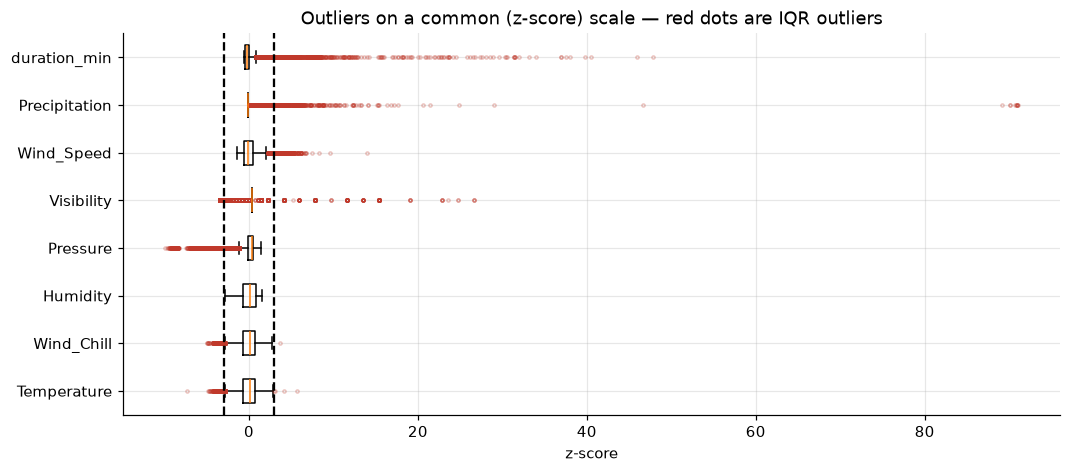

In [15]:
def outlier_table(d, cols):
    rows = []
    for c in cols:
        s = d[c].dropna(); q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        z = (s - s.mean()) / s.std()
        rows.append({"variable": c, "n": len(s), "iqr_low": int((s < lo).sum()), "iqr_high": int((s > hi).sum()),
                     "iqr_%": 100 * ((s < lo) | (s > hi)).mean(), "z>3_%": 100 * (z.abs() > 3).mean(),
                     "lower_fence": lo, "upper_fence": hi, "min": s.min(), "p1": s.quantile(.01), "median": s.median(), "p99": s.quantile(.99), "max": s.max()})
    return pd.DataFrame(rows).set_index("variable").round(2)
OUT_COLS = WEATHER_NUM + ["duration_min"]
display(outlier_table(df, OUT_COLS))
z = (df[OUT_COLS] - df[OUT_COLS].mean()) / df[OUT_COLS].std()
plt.figure(figsize=(11, 4.5))
plt.boxplot([z[c].dropna() for c in OUT_COLS], tick_labels=[c.split("(")[0] for c in OUT_COLS], vert=False, flierprops=dict(markersize=2, alpha=0.3, markeredgecolor=RED))
plt.axvline(3, ls="--", color="k"); plt.axvline(-3, ls="--", color="k"); plt.xlabel("z-score"); plt.title("Outliers on a common (z-score) scale — red dots are IQR outliers"); plt.show()

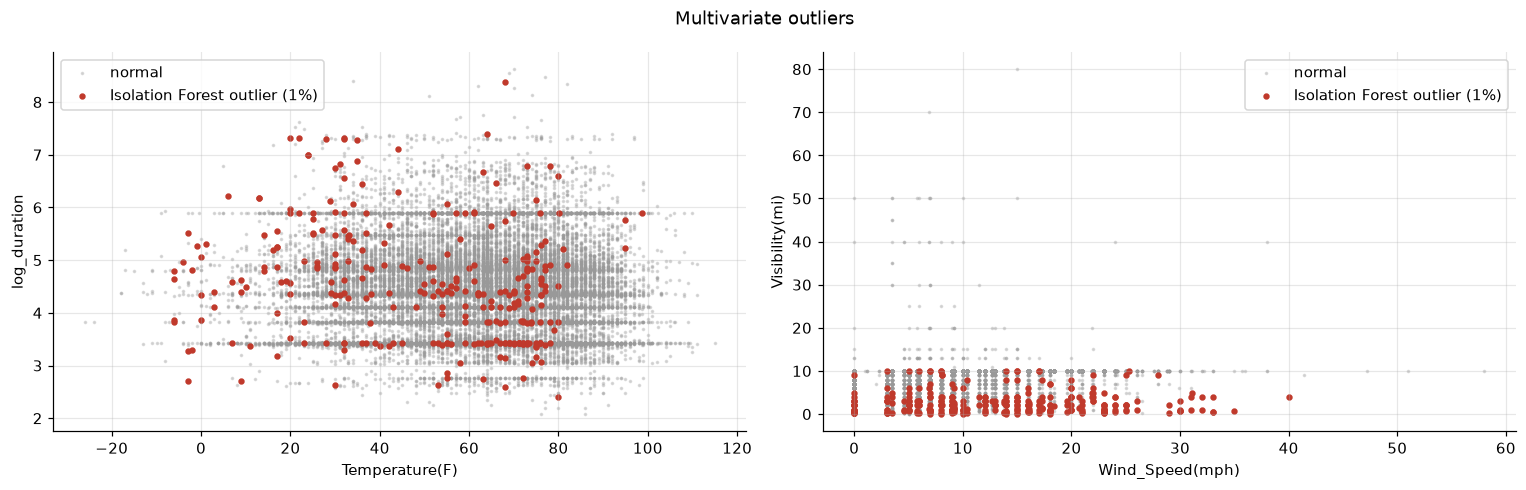

Most anomalous crashes:


,Temperature(F),Visibility(mi),Wind_Speed(mph),Precipitation(in),log_duration,hour,anomaly,score
9493,52.0,1.00,23.0,0.57,5.89,16,True,0.73
97075,77.0,0.50,24.0,0.72,4.41,18,True,0.73
133343,73.0,1.00,17.0,1.36,3.42,8,True,0.72
100881,77.0,3.00,17.0,1.70,4.82,17,True,0.72
33871,75.0,1.20,10.4,1.14,3.42,22,True,0.71
144833,56.0,2.00,23.0,0.34,4.38,1,True,0.71
113769,17.0,1.00,9.0,0.96,4.88,9,True,0.71
79225,6.0,0.25,29.0,0.00,6.21,20,True,0.71
103169,58.0,1.00,3.0,5.13,3.04,9,True,0.71
144127,20.0,9.00,28.0,0.72,4.35,13,True,0.71


In [16]:
ISO_COLS = ["Temperature(F)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "log_duration", "hour"]
Xi = df[ISO_COLS].fillna(df[ISO_COLS].median()).sample(30_000, random_state=SEED)
iso = IsolationForest(contamination=0.01, random_state=SEED).fit(Xi)
Xi = Xi.assign(anomaly=iso.predict(Xi) == -1, score=-iso.score_samples(Xi))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (xc, yc) in zip(ax, [("Temperature(F)", "log_duration"), ("Wind_Speed(mph)", "Visibility(mi)")]):
    a.scatter(Xi.loc[~Xi.anomaly, xc], Xi.loc[~Xi.anomaly, yc], s=2, alpha=0.3, color=GREY, label="normal")
    a.scatter(Xi.loc[Xi.anomaly, xc], Xi.loc[Xi.anomaly, yc], s=10, color=RED, label="Isolation Forest outlier (1%)")
    a.set(xlabel=xc, ylabel=yc); a.legend()
plt.suptitle("Multivariate outliers"); plt.tight_layout(); plt.show()
print("Most anomalous crashes:"); display(Xi.nlargest(10, "score").round(2))

**Handling decision**
- *Impossible* values (e.g. 207 °F, 470 mph wind) are sensor/recording errors → set to missing, later imputed.
- *Extreme but real* values (blizzards, multi-day closures) are kept — they are exactly the crashes we care about. Outliers are **not deleted**.
- For models, numeric features are **winsorized to the 1st–99th percentile learned on the training fold only** (inside the pipeline), so linear / distance-based models are not dominated by a few points.
- The duration target is log-transformed (skew 37 → ~0) rather than trimmed.

In [17]:
IMPOSSIBLE = {"Temperature(F)": (-60, 130), "Wind_Chill(F)": (-80, 130), "Wind_Speed(mph)": (0, 150),
              "Visibility(mi)": (0, 100), "Pressure(in)": (25, 32.5), "Precipitation(in)": (0, 10), "Humidity(%)": (0, 100)}
fixed = {c: int((df[c].notna() & ~df[c].between(lo, hi)).sum()) for c, (lo, hi) in IMPOSSIBLE.items()}
df = df.assign(**{c: df[c].where(df[c].between(lo, hi)) for c, (lo, hi) in IMPOSSIBLE.items()})
pd.Series(fixed, name="impossible values set to NaN").to_frame()

,impossible values set to NaN
Temperature(F),3
Wind_Chill(F),1
Wind_Speed(mph),0
Visibility(mi),0
Pressure(in),1891
Precipitation(in),0
Humidity(%),0


## 6. Feature engineering & split
- **Cyclical encoding** of hour / weekday / month (sin, cos) so 23:00 is next to 00:00.
- Numeric: weather + location + cyclical time + year. Binary: road flags + weekend/rush/night. Categorical: reporting source, weather group, wind direction.
- **Temporal split**: train on the earliest 80% of crashes, test on the latest 20% (realistic: predict the future). A random split is compared later.

features: 16 numeric + 15 binary + 3 categorical


,rows,from,to,severe_rate
train,119722,2016-02-08 06:15:39,2022-04-05 06:43:29,0.227277
test,29931,2022-04-05 06:49:00,2023-03-31 22:30:55,0.058434


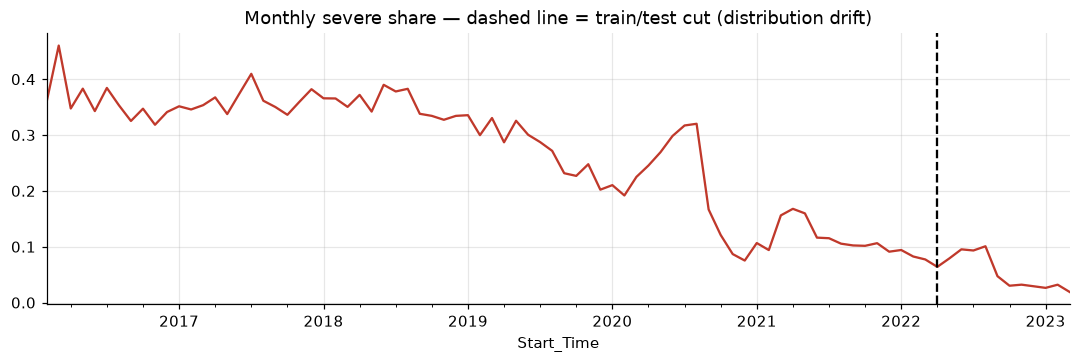

In [18]:
def cyc(s, period):
    return np.sin(2 * np.pi * s / period), np.cos(2 * np.pi * s / period)
(hs, hc), (ds, dc), (ms, mc) = cyc(df.hour, 24), cyc(df.dow, 7), cyc(df.month, 12)
df = df.assign(hour_sin=hs, hour_cos=hc, dow_sin=ds, dow_cos=dc, month_sin=ms, month_cos=mc)
NUM = WEATHER_NUM + ["Start_Lat", "Start_Lng", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "year"]
BIN = ROAD_FLAGS + ["is_weekend", "is_rush_hour", "is_night"]
CAT = ["Source", "weather_group", "Wind_Direction"]
FEATURES = NUM + BIN + CAT
tr, te = temporal_split(df)
X_tr, X_te = df.loc[tr, FEATURES], df.loc[te, FEATURES]
y_tr, y_te = df.loc[tr, "is_severe"], df.loc[te, "is_severe"]
print(f"features: {len(NUM)} numeric + {len(BIN)} binary + {len(CAT)} categorical")
display(pd.DataFrame({"rows": [tr.sum(), te.sum()], "from": [df.Start_Time[tr].min(), df.Start_Time[te].min()],
                      "to": [df.Start_Time[tr].max(), df.Start_Time[te].max()], "severe_rate": [y_tr.mean(), y_te.mean()]}, index=["train", "test"]))
mon = df.set_index("Start_Time").is_severe.resample("MS").mean()
ax = mon.plot(color=RED, figsize=(12, 3.2), title="Monthly severe share — dashed line = train/test cut (distribution drift)")
ax.axvline(df.Start_Time[te].min(), ls="--", color="k"); plt.show()

## 7. Preprocessing pipeline (fit on training data only)
`numeric → median imputation → winsorize 1–99% → StandardScaler (mean 0, sd 1)`, `binary → passthrough`, `categorical → one-hot (rare levels < 1% grouped)`.
Wrapping it in a `Pipeline` means that inside cross-validation the imputer, clipper and scaler are **re-fit on each training fold** — no leakage from the validation fold.

34 raw columns -> 66 model features


before (raw)                          after (imputed, clipped, standardized)                 
                          mean    std      min      max                                   mean  std   min   max
Temperature(F)           60.94  18.86   -27.90   120.00                                   -0.0  1.0 -2.62  1.85
Wind_Chill(F)            56.49  22.44   -52.60   120.00                                    0.0  1.0 -3.05  1.94
Humidity(%)              65.22  22.83     1.00   100.00                                    0.0  1.0 -2.37  1.54
Pressure(in)             29.65   0.76    25.00    30.92                                    0.0  1.0 -5.35  1.09
Visibility(mi)            9.07   2.74     0.00    80.00                                    0.0  1.0 -3.67  0.42
Wind_Speed(mph)           7.69   5.20     0.00    58.00                                   -0.0  1.0 -1.56  3.17
Precipitation(in)         0.01   0.12     0.00    10.00                                   -0.0  1.0 -0.20  7.42
Start_Lat                36.20   5.07    24.57    48.99                                   -0.0  1.0 -2.07  2.24
Start_Lng               -94.95  17.32  -124.49   -67.84                                   -0.0  1.0 -1.62  1.36
hour_sin                 -0.03   0.76    -1.00     1.00                                   -0.0  1.0 -1.27  1.35
hour_cos                 -0.28   0.58    -1.00     1.00                                    0.0  1.0 -1.24  2.20
dow_sin                   0.16   0.65    -0.97     0.97                                   -0.0  1.0 -1.75  1.25
dow_cos                  -0.06   0.74    -0.90     1.00                                   -0.0  1.0 -1.14  1.44
month_sin                 0.00   0.71    -1.00     1.00                                   -0.0  1.0 -1.42  1.42
month_cos                 0.12   0.70    -1.00     1.00                                    0.0  1.0 -1.61  1.25
year                   2019.36   1.72  2016.00  2022.00                                    0.0  1.0 -1.95  1.54

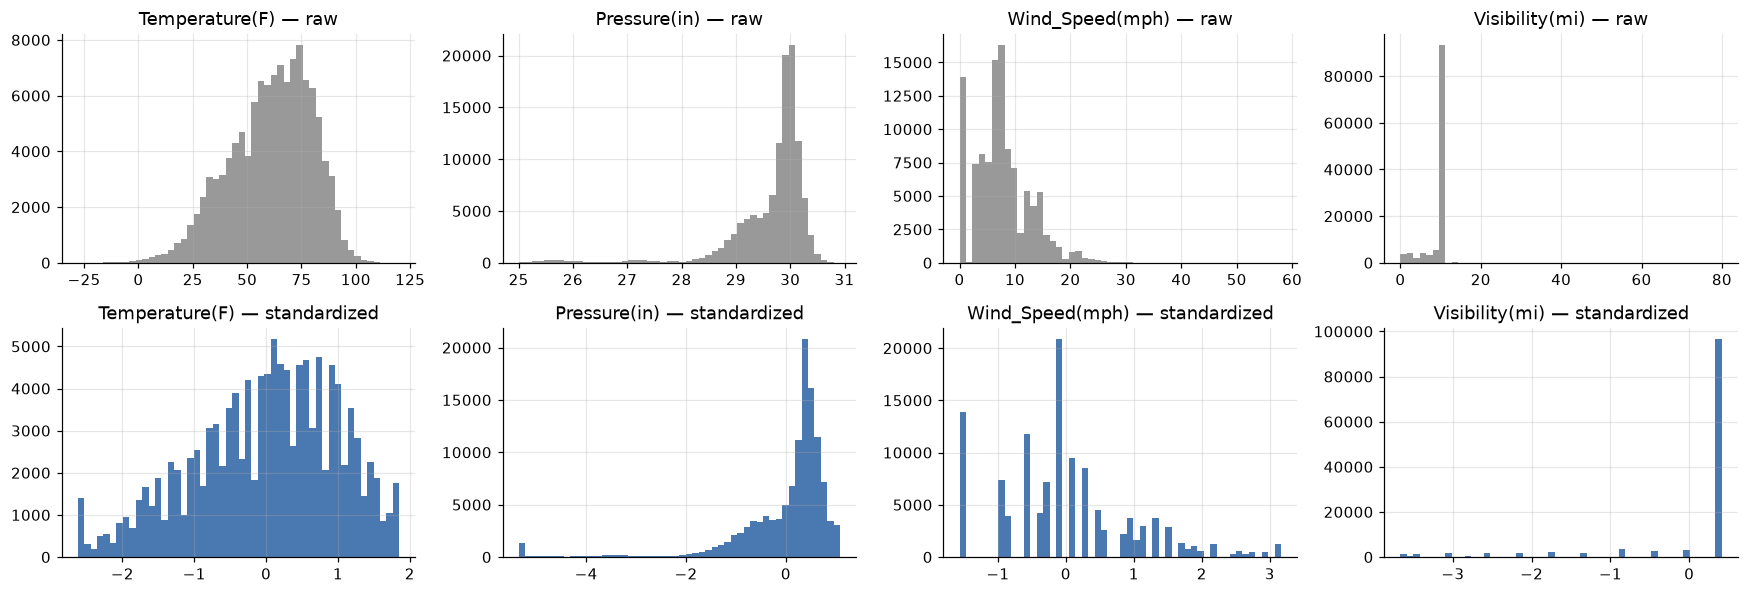

one-hot columns: ['cat__Source_Source1', 'cat__Source_Source2', 'cat__Source_Source3', 'cat__weather_group_clear', 'cat__weather_group_cloudy', 'cat__weather_group_fog', 'cat__weather_group_rain', 'cat__weather_group_snow', 'cat__weather_group_unknown', 'cat__weather_group_infrequent_sklearn', 'cat__Wind_Direction_CALM', 'cat__Wind_Direction_Calm', 'cat__Wind_Direction_E', 'cat__Wind_Direction_ENE', 'cat__Wind_Direction_ESE', 'cat__Wind_Direction_East', 'cat__Wind_Direction_N', 'cat__Wind_Direction_NE', 'cat__Wind_Direction_NNE', 'cat__Wind_Direction_NNW', 'cat__Wind_Direction_NW', 'cat__Wind_Direction_North', 'cat__Wind_Direction_S', 'cat__Wind_Direction_SE', 'cat__Wind_Direction_SSE', 'cat__Wind_Direction_SSW', 'cat__Wind_Direction_SW', 'cat__Wind_Direction_South', 'cat__Wind_Direction_VAR', 'cat__Wind_Direction_Variable', 'cat__Wind_Direction_W', 'cat__Wind_Direction_WNW', 'cat__Wind_Direction_WSW', 'cat__Wind_Direction_West', 'cat__Wind_Direction_unknown']


In [19]:
class Clipper(BaseEstimator, TransformerMixin):
    # Winsorize each column to [low, high] quantiles learned in fit().
    def __init__(self, low=0.01, high=0.99):
        self.low, self.high = low, high
    def fit(self, X, y=None):
        X = np.asarray(X, float); self.lo_, self.hi_ = np.nanquantile(X, self.low, axis=0), np.nanquantile(X, self.high, axis=0); return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)

def make_pre(num=NUM):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("clip", Clipper()), ("scale", StandardScaler())]), num),
        ("bin", "passthrough", BIN),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False), CAT)])

def make_pipe(model, num=NUM):
    return Pipeline([("pre", make_pre(num)), ("model", model)])

pre = make_pre().fit(X_tr)
Z_tr = pre.transform(X_tr); names = pre.get_feature_names_out()
print(f"{X_tr.shape[1]} raw columns -> {Z_tr.shape[1]} model features")
before = X_tr[NUM].describe().T[["mean", "std", "min", "max"]]
after = pd.DataFrame(Z_tr[:, :len(NUM)], columns=NUM).describe().T[["mean", "std", "min", "max"]]
display(pd.concat({"before (raw)": before, "after (imputed, clipped, standardized)": after}, axis=1).round(2))
fig, ax = plt.subplots(2, 4, figsize=(16, 5.5))
for j, col in enumerate(["Temperature(F)", "Pressure(in)", "Wind_Speed(mph)", "Visibility(mi)"]):
    ax[0, j].hist(X_tr[col].dropna(), bins=50, color=GREY); ax[0, j].set_title(f"{col} — raw")
    ax[1, j].hist(Z_tr[:, NUM.index(col)], bins=50, color=BLUE); ax[1, j].set_title(f"{col} — standardized")
plt.tight_layout(); plt.show()
print("one-hot columns:", [n for n in names if n.startswith("cat__")])

## 8. Cross-validation setup & metric glossary
- **Stratified K-fold (K=5)** for classification: every fold keeps the 22% severe share.
- **K-fold (K=5, shuffled)** for regression.
- **TimeSeriesSplit** (rolling origin) for forecasting — never trains on the future.
- CV runs on a 40k-row random subset of the *training* period; the untouched temporal test set is used once at the end.

| Metric | Meaning |
|---|---|
| Accuracy | share correct (misleading when 78% are "not severe") |
| Balanced accuracy | mean recall over classes (0.5 = chance) |
| Precision / Recall / F1 | for the severe class; F1 = harmonic mean |
| Macro F1 | F1 averaged over classes equally |
| ROC-AUC | probability a random severe crash is ranked above a random non-severe one (0.5 chance, 1 perfect) |
| PR-AUC | area under precision–recall (baseline = prevalence 0.22) |
| Log loss / Brier | quality of predicted probabilities (lower better) |
| MAE / RMSE / MedAE | regression errors (RMSE punishes big misses) |
| R² | share of variance explained (0 = predicting the mean) |
| MAPE | mean absolute % error (forecasting) |
| Silhouette / Davies–Bouldin / Calinski–Harabasz | cluster separation (higher / lower / higher better) |

,train_rows,valid_rows,valid_severe_rate
fold,,,
1,32000,8000,0.2271
2,32000,8000,0.2271
3,32000,8000,0.2271
4,32000,8000,0.2271
5,32000,8000,0.2271


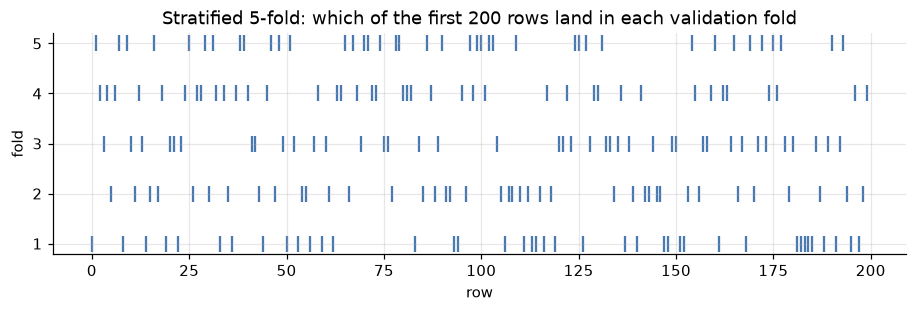

In [20]:
cv_idx = rng.choice(np.flatnonzero(tr), CV_N, replace=False)
X_cv, y_cv = df.loc[cv_idx, FEATURES], df.loc[cv_idx, "is_severe"]
skf = StratifiedKFold(K, shuffle=True, random_state=SEED)
folds = pd.DataFrame([{"fold": i + 1, "train_rows": len(a), "valid_rows": len(b), "valid_severe_rate": y_cv.iloc[b].mean()}
                      for i, (a, b) in enumerate(skf.split(X_cv, y_cv))]).set_index("fold")
display(folds.round(4))
fig, ax = plt.subplots(figsize=(10, 2.6))
for i, (a, b) in enumerate(skf.split(X_cv[:200], y_cv[:200])):
    ax.scatter(b, [i + 1] * len(b), marker="|", s=120, color=BLUE)
ax.set(title="Stratified 5-fold: which of the first 200 rows land in each validation fold", xlabel="row", ylabel="fold", yticks=range(1, 6)); plt.show()

## 9. Classification — predict whether a crash is severe (Severity 3–4)
### 9.1 Eight models, stratified 5-fold CV

In [21]:
CLS = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Gaussian naive Bayes": GaussianNB(),
    "k-nearest neighbours (k=25)": KNeighborsClassifier(25, n_jobs=-1),
    "Decision tree": DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=SEED),
    "Random forest": RandomForestClassifier(200, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=SEED),
    "Gradient boosting (HGB)": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED),
    "Neural network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=SEED),
}
SCORING = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv_cls = {}
for name, m in CLS.items():
    t0 = time.time()
    cv_cls[name] = cross_validate(make_pipe(m), X_cv, y_cv, cv=skf, scoring=SCORING, n_jobs=1)
    print(f"{name:32s} done in {time.time() - t0:5.1f}s")
cv_table = pd.DataFrame({n: {k: f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}" for k in SCORING} | {"fit_sec": round(r["fit_time"].mean(), 2)}
                         for n, r in cv_cls.items()}).T
cv_table

Dummy (majority class)           done in   0.9s


Logistic regression              done in   1.1s


Gaussian naive Bayes             done in   1.0s


k-nearest neighbours (k=25)      done in   5.9s


Decision tree                    done in   2.3s


Random forest                    done in   5.4s


Gradient boosting (HGB)          done in  20.1s


Neural network (MLP)             done in   8.2s


,accuracy,balanced_acc,f1_macro,roc_auc,pr_auc,fit_sec
Dummy (majority class),0.773 ± 0.000,0.500 ± 0.000,0.436 ± 0.000,0.500 ± 0.000,0.227 ± 0.000,0.14
Logistic regression,0.782 ± 0.004,0.597 ± 0.007,0.609 ± 0.009,0.789 ± 0.002,0.487 ± 0.011,0.19
Gaussian naive Bayes,0.430 ± 0.074,0.597 ± 0.028,0.425 ± 0.070,0.718 ± 0.002,0.394 ± 0.010,0.15
k-nearest neighbours (k=25),0.777 ± 0.001,0.556 ± 0.002,0.552 ± 0.003,0.763 ± 0.006,0.439 ± 0.010,0.19
Decision tree,0.803 ± 0.003,0.674 ± 0.008,0.689 ± 0.006,0.832 ± 0.001,0.548 ± 0.009,0.42
Random forest,0.808 ± 0.004,0.627 ± 0.007,0.648 ± 0.008,0.851 ± 0.004,0.594 ± 0.016,0.96
Gradient boosting (HGB),0.829 ± 0.004,0.707 ± 0.005,0.728 ± 0.006,0.872 ± 0.002,0.652 ± 0.013,3.92
Neural network (MLP),0.791 ± 0.004,0.622 ± 0.016,0.637 ± 0.017,0.825 ± 0.004,0.529 ± 0.013,1.61


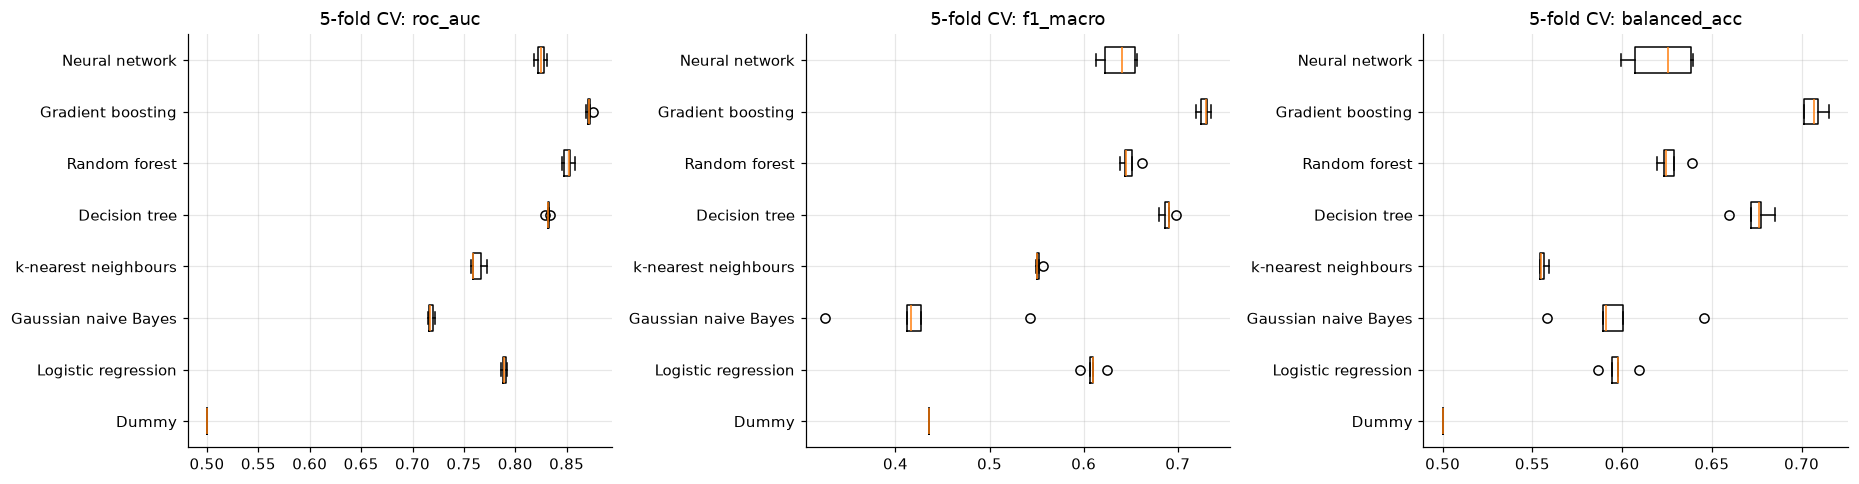

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, k in zip(ax, ["roc_auc", "f1_macro", "balanced_acc"]):
    a.boxplot([cv_cls[n]["test_" + k] for n in CLS], tick_labels=[n.split(" (")[0] for n in CLS], vert=False)
    a.set_title(f"5-fold CV: {k}")
plt.tight_layout(); plt.show()

### 9.2 Fit on the full training period, evaluate once on the future test set

In [23]:
fitted = {}
for name, m in CLS.items():
    Xf, yf = (X_cv, y_cv) if name.startswith("k-nearest") else (X_tr, y_tr)   # kNN: 40k reference points keeps prediction fast
    fitted[name] = make_pipe(m).fit(Xf, yf)
proba = {n: p.predict_proba(X_te)[:, 1] for n, p in fitted.items()}

def cls_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"accuracy": M.accuracy_score(y, pred), "balanced_acc": M.balanced_accuracy_score(y, pred),
            "precision": M.precision_score(y, pred, zero_division=0), "recall": M.recall_score(y, pred),
            "f1": M.f1_score(y, pred), "f1_macro": M.f1_score(y, pred, average="macro"),
            "roc_auc": M.roc_auc_score(y, p), "pr_auc": M.average_precision_score(y, p),
            "log_loss": M.log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "brier": M.brier_score_loss(y, p)}
test_cls = pd.DataFrame({n: cls_metrics(y_te, p) for n, p in proba.items()}).T
display(test_cls.round(3).style.highlight_max(subset=["balanced_acc", "f1", "f1_macro", "roc_auc", "pr_auc"], color="#cfe0f5")
        .highlight_min(subset=["log_loss", "brier"], color="#cfe0f5").format("{:.3f}"))

,accuracy,balanced_acc,precision,recall,f1,f1_macro,roc_auc,pr_auc,log_loss,brier
Dummy (majority class),0.942,0.500,0.000,0.000,0.000,0.485,0.500,0.058,0.807,0.058
Logistic regression,0.942,0.504,0.625,0.009,0.017,0.493,0.755,0.335,0.195,0.048
Gaussian naive Bayes,0.483,0.590,0.077,0.711,0.138,0.384,0.646,0.133,2.357,0.472
k-nearest neighbours (k=25),0.943,0.519,0.636,0.040,0.075,0.523,0.751,0.236,0.238,0.052
Decision tree,0.946,0.626,0.590,0.264,0.364,0.668,0.832,0.393,0.183,0.043
Random forest,0.949,0.606,0.692,0.217,0.331,0.652,0.838,0.430,0.165,0.042
Gradient boosting (HGB),0.951,0.632,0.704,0.270,0.391,0.683,0.854,0.469,0.156,0.040
Neural network (MLP),0.947,0.617,0.605,0.243,0.347,0.659,0.826,0.383,0.177,0.044


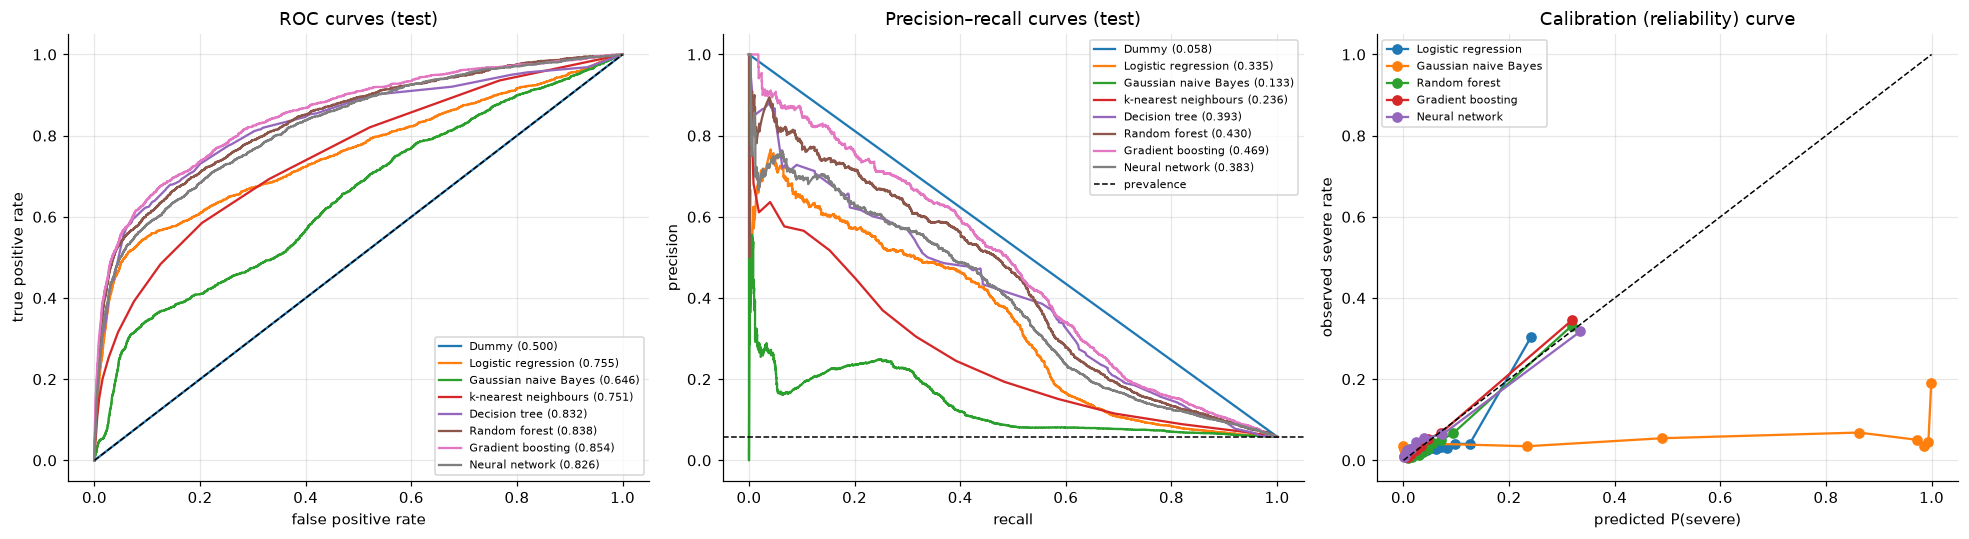

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n, p in proba.items():
    fpr, tpr, _ = M.roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{n.split(' (')[0]} ({M.roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = M.precision_recall_curve(y_te, p); ax[1].plot(rc, pr, label=f"{n.split(' (')[0]} ({M.average_precision_score(y_te, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC curves (test)", xlabel="false positive rate", ylabel="true positive rate"); ax[0].legend(fontsize=7)
ax[1].axhline(y_te.mean(), color="k", ls="--", lw=1, label="prevalence"); ax[1].set(title="Precision–recall curves (test)", xlabel="recall", ylabel="precision"); ax[1].legend(fontsize=7)
for n in ["Logistic regression", "Gaussian naive Bayes", "Random forest", "Gradient boosting (HGB)", "Neural network (MLP)"]:
    fo, mp = calibration_curve(y_te, proba[n], n_bins=10, strategy="quantile"); ax[2].plot(mp, fo, marker="o", label=n.split(" (")[0])
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set(title="Calibration (reliability) curve", xlabel="predicted P(severe)", ylabel="observed severe rate"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 9.3 Decision threshold (chosen on out-of-fold CV predictions, not on the test set)

best model by test ROC-AUC: Gradient boosting (HGB)


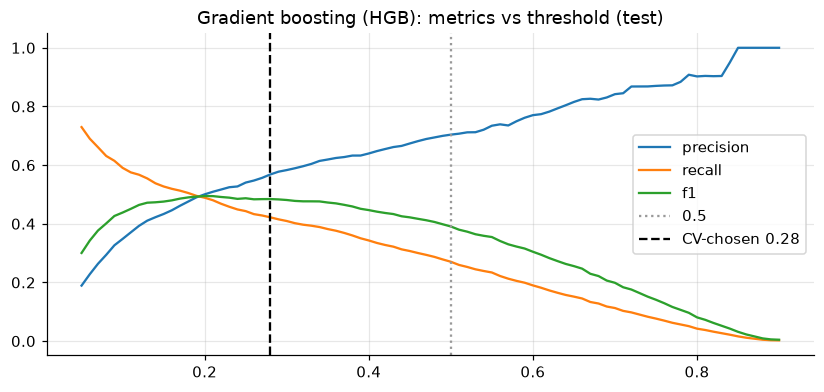

,accuracy,balanced_acc,precision,recall,f1,f1_macro,roc_auc,pr_auc,log_loss,brier
threshold 0.50,0.951,0.632,0.704,0.270,0.391,0.683,0.854,0.469,0.156,0.04
threshold 0.28,0.947,0.701,0.568,0.422,0.484,0.728,0.854,0.469,0.156,0.04


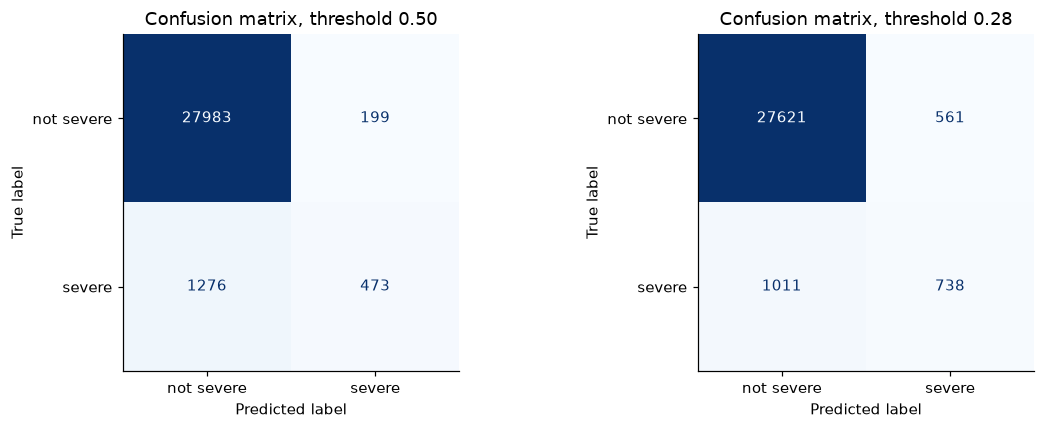

              precision    recall  f1-score   support

  not severe      0.965     0.980     0.972     28182
      severe      0.568     0.422     0.484      1749

    accuracy                          0.947     29931
   macro avg      0.766     0.701     0.728     29931
weighted avg      0.942     0.947     0.944     29931



In [25]:
best_name = test_cls.roc_auc.drop("Dummy (majority class)").idxmax()
print("best model by test ROC-AUC:", best_name)
oof = cross_val_predict(make_pipe(clone(CLS[best_name])), X_cv, y_cv, cv=skf, method="predict_proba")[:, 1]
thr_grid = np.linspace(0.05, 0.9, 86)
f1s = [M.f1_score(y_cv, oof >= t) for t in thr_grid]
best_thr = thr_grid[int(np.argmax(f1s))]
p_best = proba[best_name]
curve = pd.DataFrame({"precision": [M.precision_score(y_te, p_best >= t, zero_division=0) for t in thr_grid],
                      "recall": [M.recall_score(y_te, p_best >= t) for t in thr_grid],
                      "f1": [M.f1_score(y_te, p_best >= t) for t in thr_grid]}, index=thr_grid)
ax = curve.plot(figsize=(9, 3.8), title=f"{best_name}: metrics vs threshold (test)")
ax.axvline(0.5, color=GREY, ls=":", label="0.5"); ax.axvline(best_thr, color="k", ls="--", label=f"CV-chosen {best_thr:.2f}"); ax.legend(); plt.show()
display(pd.DataFrame({"threshold 0.50": cls_metrics(y_te, p_best, 0.5), f"threshold {best_thr:.2f}": cls_metrics(y_te, p_best, best_thr)}).T.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, t in zip(ax, [0.5, best_thr]):
    M.ConfusionMatrixDisplay.from_predictions(y_te, (p_best >= t).astype(int), display_labels=["not severe", "severe"], ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Confusion matrix, threshold {t:.2f}"); a.grid(False)
plt.tight_layout(); plt.show()
print(M.classification_report(y_te, (p_best >= best_thr).astype(int), target_names=["not severe", "severe"], digits=3))

### 9.4 Hyper-parameter tuning (randomized search, stratified 5-fold, ROC-AUC)

,rank_test_score,mean_test_score,std_test_score,param_model__l2_regularization,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf
10,1,0.8754,0.0018,0.0720,0.0252,93,87
1,2,0.8751,0.0022,0.1456,0.1019,88,37
3,3,0.8747,0.0029,1.2295,0.0547,116,125
4,4,0.8742,0.0024,0.0187,0.0961,65,86
9,5,0.8741,0.0029,0.2296,0.0218,95,147
7,6,0.8741,0.0023,0.4018,0.0483,68,146
8,7,0.8725,0.0029,0.0262,0.1258,98,180
0,8,0.8716,0.0030,0.0034,0.1401,39,176


best params: {'model__l2_regularization': np.float64(0.07202792123795003), 'model__learning_rate': np.float64(0.025213146669353953), 'model__max_leaf_nodes': 93, 'model__min_samples_leaf': 87}


,accuracy,balanced_acc,precision,recall,f1,f1_macro,roc_auc,pr_auc,log_loss,brier
HGB default,0.951,0.632,0.704,0.270,0.391,0.683,0.854,0.469,0.156,0.04
HGB tuned,0.952,0.646,0.712,0.299,0.421,0.698,0.856,0.480,0.155,0.04


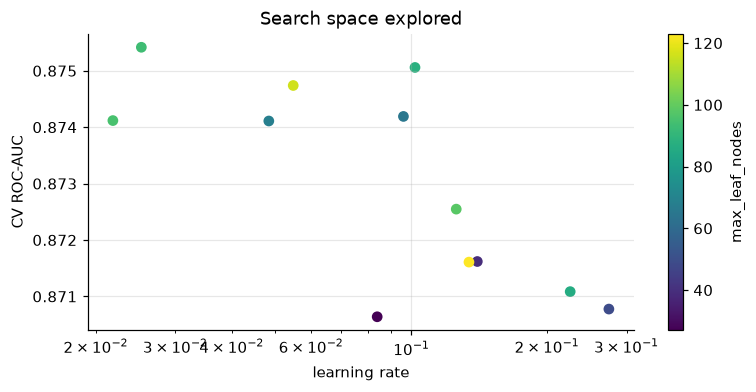

In [26]:
space = {"model__learning_rate": loguniform(0.02, 0.3), "model__max_leaf_nodes": randint(15, 128),
         "model__min_samples_leaf": randint(10, 200), "model__l2_regularization": loguniform(1e-3, 10)}
search = RandomizedSearchCV(make_pipe(HistGradientBoostingClassifier(max_iter=300, random_state=SEED)), space, n_iter=12,
                            scoring="roc_auc", cv=skf, random_state=SEED, n_jobs=1).fit(X_cv, y_cv)
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(res[["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in res if c.startswith("param_")]].head(8).round(4))
tuned = clone(search.best_estimator_).fit(X_tr, y_tr)
p_tuned = tuned.predict_proba(X_te)[:, 1]
print("best params:", search.best_params_)
display(pd.DataFrame({"HGB default": cls_metrics(y_te, proba["Gradient boosting (HGB)"]), "HGB tuned": cls_metrics(y_te, p_tuned)}).T.round(3))
plt.figure(figsize=(8, 3.5)); plt.scatter(res.param_model__learning_rate.astype(float), res.mean_test_score, c=res.param_model__max_leaf_nodes.astype(float), cmap="viridis")
plt.colorbar(label="max_leaf_nodes"); plt.xscale("log"); plt.xlabel("learning rate"); plt.ylabel("CV ROC-AUC"); plt.title("Search space explored"); plt.show()

### 9.5 Class imbalance: class weights

In [27]:
bal = make_pipe(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, class_weight="balanced", random_state=SEED)).fit(X_tr, y_tr)
p_bal = bal.predict_proba(X_te)[:, 1]
display(pd.DataFrame({"HGB unweighted": cls_metrics(y_te, proba["Gradient boosting (HGB)"]), "HGB class_weight='balanced'": cls_metrics(y_te, p_bal)}).T.round(3))
print("Balancing trades precision and calibration for recall of the rare severe class; ROC-AUC (ranking) barely changes.")

,accuracy,balanced_acc,precision,recall,f1,f1_macro,roc_auc,pr_auc,log_loss,brier
HGB unweighted,0.951,0.632,0.704,0.270,0.391,0.683,0.854,0.469,0.156,0.040
HGB class_weight='balanced',0.945,0.718,0.533,0.461,0.495,0.733,0.852,0.460,0.184,0.047


Balancing trades precision and calibration for recall of the rare severe class; ROC-AUC (ranking) barely changes.


### 9.6 Random split vs temporal split (why the honest test is harder)

In [28]:
idx_a, idx_b = train_test_split(np.arange(len(df)), test_size=0.2, stratify=df.is_severe, random_state=SEED)
rnd = make_pipe(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED)).fit(df.loc[idx_a, FEATURES], df.loc[idx_a, "is_severe"])
p_rnd = rnd.predict_proba(df.loc[idx_b, FEATURES])[:, 1]
cmp = pd.DataFrame({"random 80/20 split": cls_metrics(df.loc[idx_b, "is_severe"], p_rnd), "temporal split (future)": cls_metrics(y_te, proba["Gradient boosting (HGB)"])}).T
display(cmp[["balanced_acc", "f1_macro", "roc_auc", "pr_auc"]].round(3))
print("The gap = how much severity labelling / coverage drifts over time (Source mix changes after 2020).")

,balanced_acc,f1_macro,roc_auc,pr_auc
random 80/20 split,0.730,0.756,0.897,0.686
temporal split (future),0.632,0.683,0.854,0.469


The gap = how much severity labelling / coverage drifts over time (Source mix changes after 2020).


### 9.7 Four-class severity (1–4)

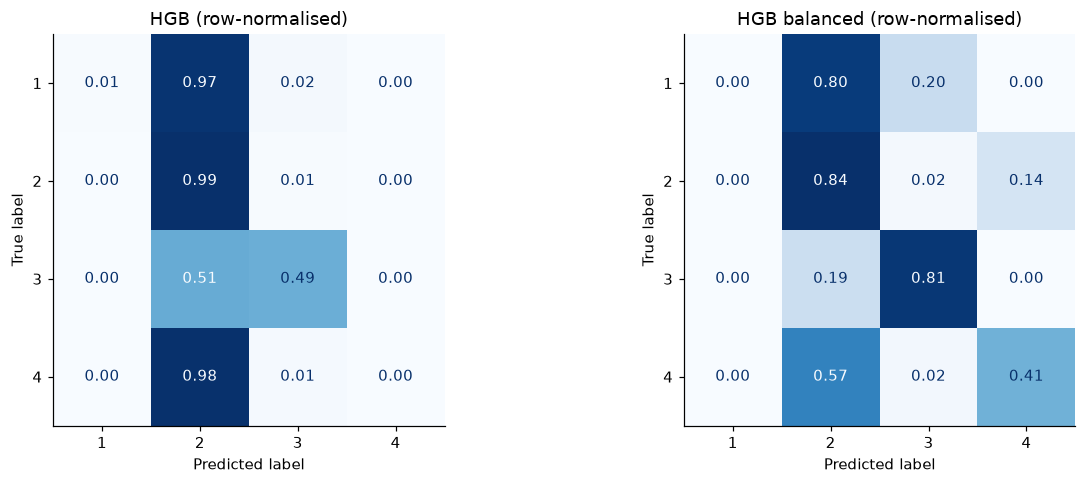

,accuracy,balanced_acc,macro_f1,weighted_f1
HGB,0.922,0.372,0.386,0.898
HGB balanced,0.803,0.514,0.414,0.839


              precision    recall  f1-score   support

           1      0.000     0.000     0.000       743
           2      0.949     0.837     0.889     27439
           3      0.521     0.812     0.635       930
           4      0.078     0.407     0.130       819

    accuracy                          0.803     29931
   macro avg      0.387     0.514     0.414     29931
weighted avg      0.888     0.803     0.839     29931



In [29]:
y4_tr, y4_te = df.loc[tr, "Severity"], df.loc[te, "Severity"]
mc = {"HGB": make_pipe(HistGradientBoostingClassifier(max_iter=300, random_state=SEED)).fit(X_tr, y4_tr),
      "HGB balanced": make_pipe(HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED)).fit(X_tr, y4_tr)}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
rows = {}
for a, (n, m) in zip(ax, mc.items()):
    pr = m.predict(X_te)
    rows[n] = {"accuracy": M.accuracy_score(y4_te, pr), "balanced_acc": M.balanced_accuracy_score(y4_te, pr), "macro_f1": M.f1_score(y4_te, pr, average="macro"),
               "weighted_f1": M.f1_score(y4_te, pr, average="weighted")}
    M.ConfusionMatrixDisplay.from_predictions(y4_te, pr, normalize="true", ax=a, cmap="Blues", colorbar=False, values_format=".2f"); a.set_title(f"{n} (row-normalised)"); a.grid(False)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T.round(3))
print(M.classification_report(y4_te, mc["HGB balanced"].predict(X_te), digits=3, zero_division=0))

### 9.8 What drives the predictions? (permutation importance + logistic coefficients)

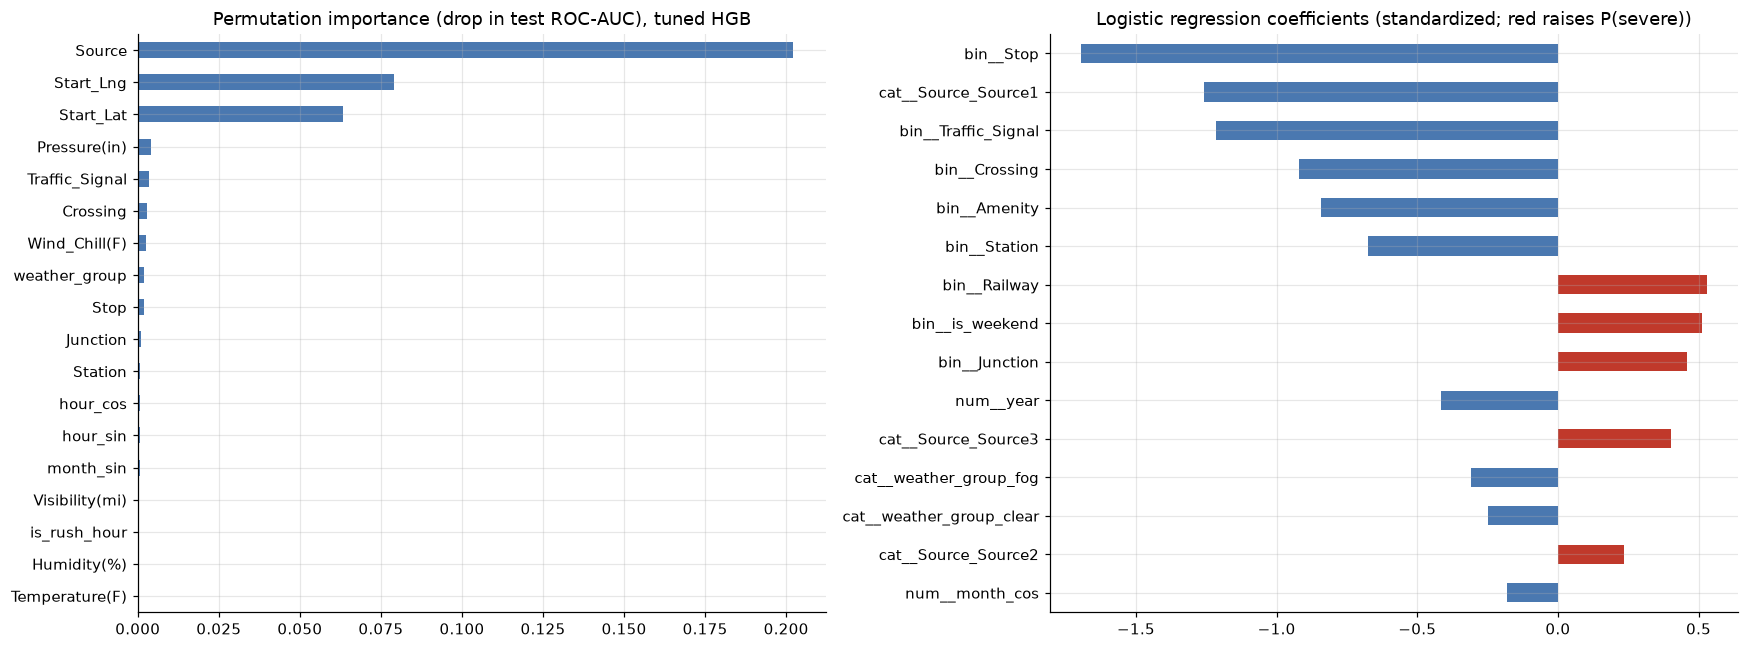

In [30]:
sub = rng.choice(len(X_te), 8000, replace=False)
pi = permutation_importance(tuned, X_te.iloc[sub], y_te.iloc[sub], scoring="roc_auc", n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
lr = fitted["Logistic regression"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
coef = coef.reindex(coef.abs().sort_values().index).tail(15)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
imp.tail(18).plot.barh(ax=ax[0], color=BLUE, title="Permutation importance (drop in test ROC-AUC), tuned HGB")
coef.plot.barh(ax=ax[1], color=[RED if v > 0 else BLUE for v in coef], title="Logistic regression coefficients (standardized; red raises P(severe))")
plt.tight_layout(); plt.show()
best_cls = test_cls.drop("Dummy (majority class)").roc_auc.idxmax()
SUMMARY.append({"task": "Classification (severe vs not)", "best model": "HGB tuned", "key metric": "ROC-AUC (future test)",
                "value": M.roc_auc_score(y_te, p_tuned), "baseline": 0.5, "other": f"macro F1 {cls_metrics(y_te, p_tuned, best_thr)['f1_macro']:.3f} @thr {best_thr:.2f}"})

## 10. Regression — predict traffic-delay duration
Target: `log(1 + minutes)`. Severity is added as a feature (it is recorded when the incident is logged). Errors are reported on the log scale and in minutes.

In [31]:
NUM_R = NUM + ["Severity"]
FEAT_R = NUM_R + BIN + CAT
Xr_tr, Xr_te = df.loc[tr, FEAT_R], df.loc[te, FEAT_R]
yr_tr, yr_te = df.loc[tr, "log_duration"], df.loc[te, "log_duration"]
Xr_cv, yr_cv = df.loc[cv_idx, FEAT_R], df.loc[cv_idx, "log_duration"]
REG = {
    "Dummy (mean)": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Ridge (L2, α=10)": Ridge(alpha=10),
    "Lasso (L1, α=0.002)": Lasso(alpha=0.002, max_iter=5000),
    "k-nearest neighbours (k=25)": KNeighborsRegressor(25, n_jobs=-1),
    "Decision tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Random forest": RandomForestRegressor(200, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=SEED),
    "Gradient boosting (HGB)": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, random_state=SEED),
    "Neural network (MLP)": MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=SEED),
}
mae_min = M.make_scorer(lambda y, p: M.mean_absolute_error(np.expm1(y), np.expm1(p)), greater_is_better=False)
RSC = {"MAE_log": "neg_mean_absolute_error", "RMSE_log": "neg_root_mean_squared_error", "R2_log": "r2", "MAE_minutes": mae_min}
kf = KFold(K, shuffle=True, random_state=SEED)
cv_reg = {}
for name, m in REG.items():
    t0 = time.time(); cv_reg[name] = cross_validate(make_pipe(m, NUM_R), Xr_cv, yr_cv, cv=kf, scoring=RSC, n_jobs=1)
    print(f"{name:32s} done in {time.time() - t0:5.1f}s")
sign = {"MAE_log": -1, "RMSE_log": -1, "R2_log": 1, "MAE_minutes": -1}
pd.DataFrame({n: {k: f"{sign[k] * r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}" for k in RSC} for n, r in cv_reg.items()}).T

Dummy (mean)                     done in   0.8s


Linear regression                done in   1.0s


Ridge (L2, α=10)                 done in   0.8s


Lasso (L1, α=0.002)              done in   0.9s


k-nearest neighbours (k=25)      done in   3.6s


Decision tree                    done in   2.6s


Random forest                    done in  25.1s


Gradient boosting (HGB)          done in  13.9s


Neural network (MLP)             done in  17.7s


,MAE_log,RMSE_log,R2_log,MAE_minutes
Dummy (mean),0.692 ± 0.005,0.854 ± 0.006,-0.000 ± 0.000,76.457 ± 1.875
Linear regression,0.556 ± 0.006,0.731 ± 0.007,0.269 ± 0.006,66.698 ± 1.952
"Ridge (L2, α=10)",0.556 ± 0.006,0.731 ± 0.007,0.269 ± 0.006,66.699 ± 1.950
"Lasso (L1, α=0.002)",0.557 ± 0.006,0.731 ± 0.007,0.267 ± 0.006,66.785 ± 1.930
k-nearest neighbours (k=25),0.531 ± 0.005,0.709 ± 0.008,0.312 ± 0.006,64.839 ± 1.923
Decision tree,0.381 ± 0.007,0.560 ± 0.011,0.570 ± 0.013,44.985 ± 1.979
Random forest,0.366 ± 0.005,0.533 ± 0.010,0.611 ± 0.010,43.618 ± 1.935
Gradient boosting (HGB),0.382 ± 0.006,0.541 ± 0.011,0.599 ± 0.011,45.121 ± 1.967
Neural network (MLP),0.440 ± 0.004,0.601 ± 0.006,0.504 ± 0.006,54.297 ± 0.968


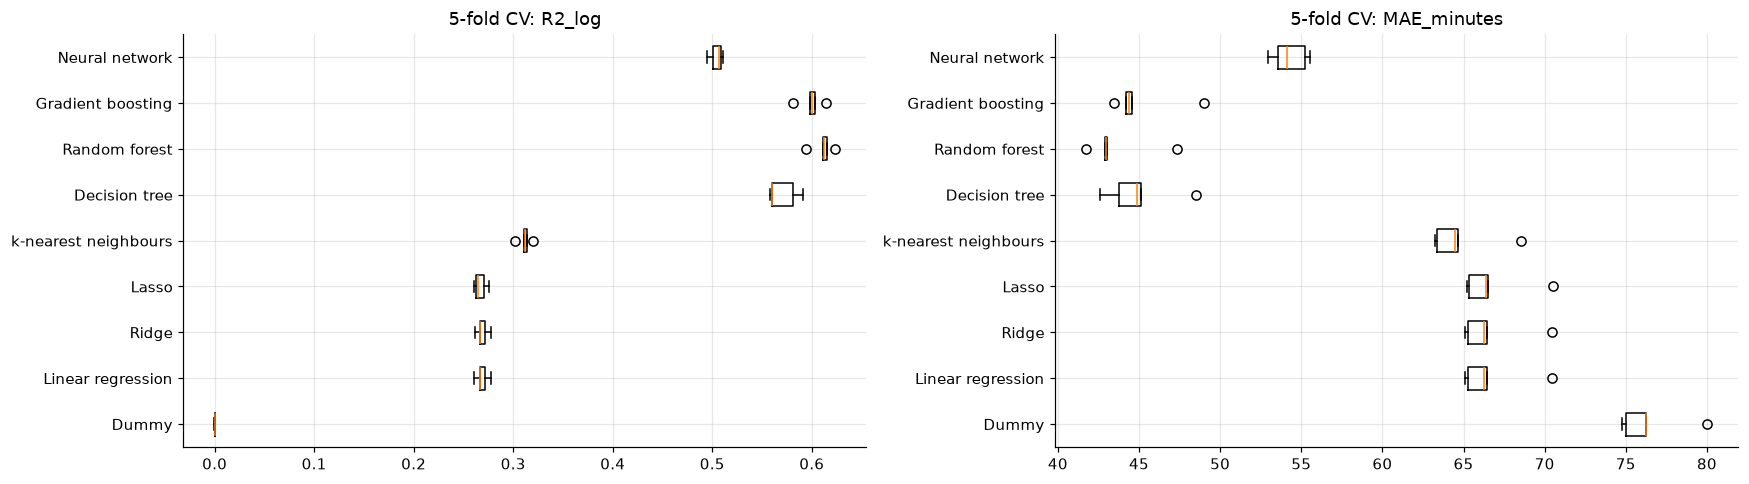

,MAE_log,RMSE_log,R2_log,MAE_min,MedAE_min,RMSE_min
Dummy (mean),0.564,0.765,-0.087,67.508,38.576,195.060
Linear regression,0.501,0.708,0.069,63.336,30.373,188.056
"Ridge (L2, α=10)",0.501,0.708,0.069,63.337,30.376,188.054
"Lasso (L1, α=0.002)",0.504,0.710,0.064,63.598,30.793,187.733
k-nearest neighbours (k=25),0.535,0.738,-0.012,66.293,34.573,189.744
Decision tree,0.499,0.709,0.066,63.379,28.835,188.709
Random forest,0.488,0.696,0.099,61.974,28.184,188.040
Gradient boosting (HGB),0.484,0.691,0.112,61.564,28.306,187.206
Neural network (MLP),0.537,0.743,-0.027,65.574,31.099,191.718


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for a, k in zip(ax, ["R2_log", "MAE_minutes"]):
    a.boxplot([sign[k] * cv_reg[n]["test_" + k] for n in REG], tick_labels=[n.split(" (")[0] for n in REG], vert=False); a.set_title(f"5-fold CV: {k}")
plt.tight_layout(); plt.show()

fit_r = {}
for name, m in REG.items():
    Xf, yf = (Xr_cv, yr_cv) if name.startswith("k-nearest") else (Xr_tr, yr_tr)
    fit_r[name] = make_pipe(m, NUM_R).fit(Xf, yf)
pred_r = {n: p.predict(Xr_te) for n, p in fit_r.items()}
def reg_metrics(y, p):
    ym, pm = np.expm1(y), np.expm1(p)
    return {"MAE_log": M.mean_absolute_error(y, p), "RMSE_log": M.root_mean_squared_error(y, p), "R2_log": M.r2_score(y, p),
            "MAE_min": M.mean_absolute_error(ym, pm), "MedAE_min": M.median_absolute_error(ym, pm), "RMSE_min": M.root_mean_squared_error(ym, pm)}
test_reg = pd.DataFrame({n: reg_metrics(yr_te, p) for n, p in pred_r.items()}).T
test_reg.round(3).style.highlight_min(subset=["MAE_log", "RMSE_log", "MAE_min", "MedAE_min", "RMSE_min"], color="#cfe0f5").highlight_max(subset=["R2_log"], color="#cfe0f5").format("{:.3f}")

best regression model (test R² on log scale): Gradient boosting (HGB)


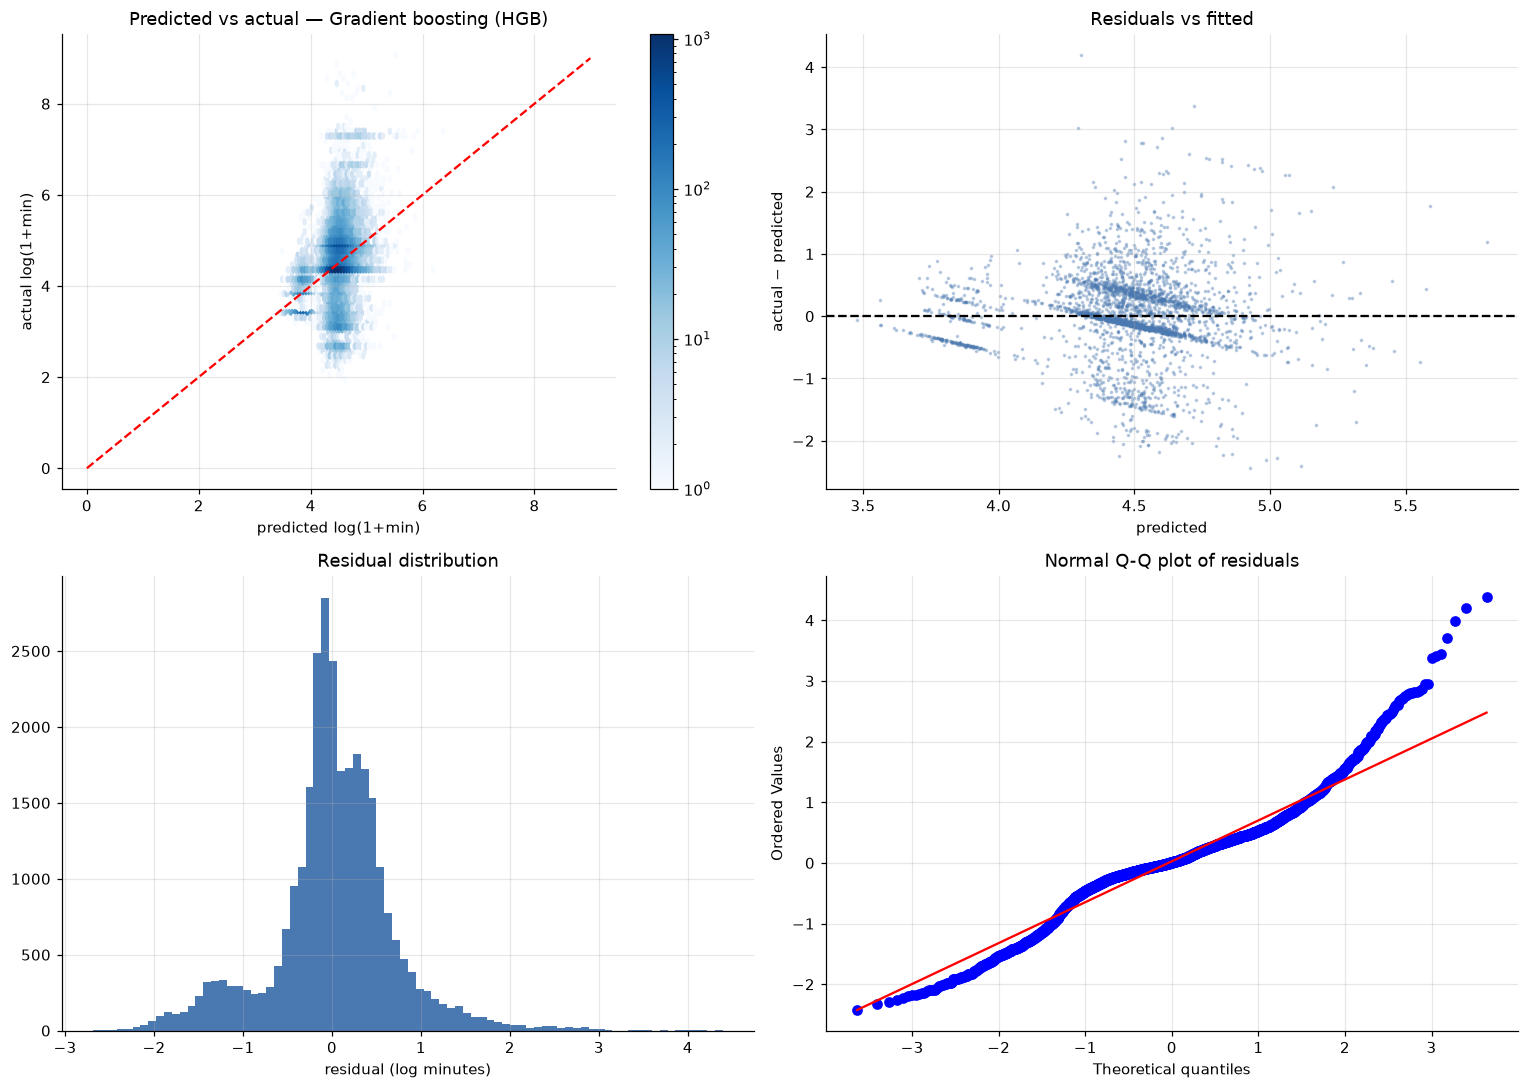

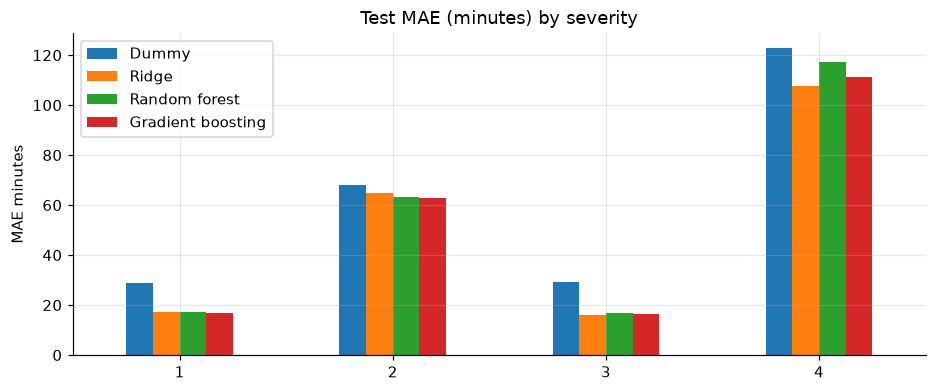

In [33]:
best_r = test_reg.drop("Dummy (mean)").R2_log.idxmax(); p = pred_r[best_r]; res_ = yr_te - p
print("best regression model (test R² on log scale):", best_r)
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
hb = ax[0, 0].hexbin(p, yr_te, gridsize=60, bins="log", cmap="Blues"); ax[0, 0].plot([0, 9], [0, 9], "r--")
ax[0, 0].set(title=f"Predicted vs actual — {best_r}", xlabel="predicted log(1+min)", ylabel="actual log(1+min)"); plt.colorbar(hb, ax=ax[0, 0])
ax[0, 1].scatter(p[::10], res_.to_numpy()[::10], s=2, alpha=0.3, color=BLUE); ax[0, 1].axhline(0, color="k", ls="--")
ax[0, 1].set(title="Residuals vs fitted", xlabel="predicted", ylabel="actual − predicted")
ax[1, 0].hist(res_, bins=80, color=BLUE); ax[1, 0].set(title="Residual distribution", xlabel="residual (log minutes)")
stats.probplot(res_.sample(5000, random_state=SEED), dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()
bysev = pd.DataFrame({n.split(" (")[0]: [M.mean_absolute_error(np.expm1(yr_te[df.loc[te, "Severity"] == s]), np.expm1(pred_r[n][(df.loc[te, "Severity"] == s).to_numpy()]))
                       for s in (1, 2, 3, 4)] for n in ["Dummy (mean)", "Ridge (L2, α=10)", "Random forest", "Gradient boosting (HGB)"]}, index=[1, 2, 3, 4])
bysev.plot.bar(rot=0, figsize=(10, 3.8), title="Test MAE (minutes) by severity"); plt.ylabel("MAE minutes"); plt.show()

### 10.1 Regularization (Ridge α validation curve, Lasso coefficients) and learning curve

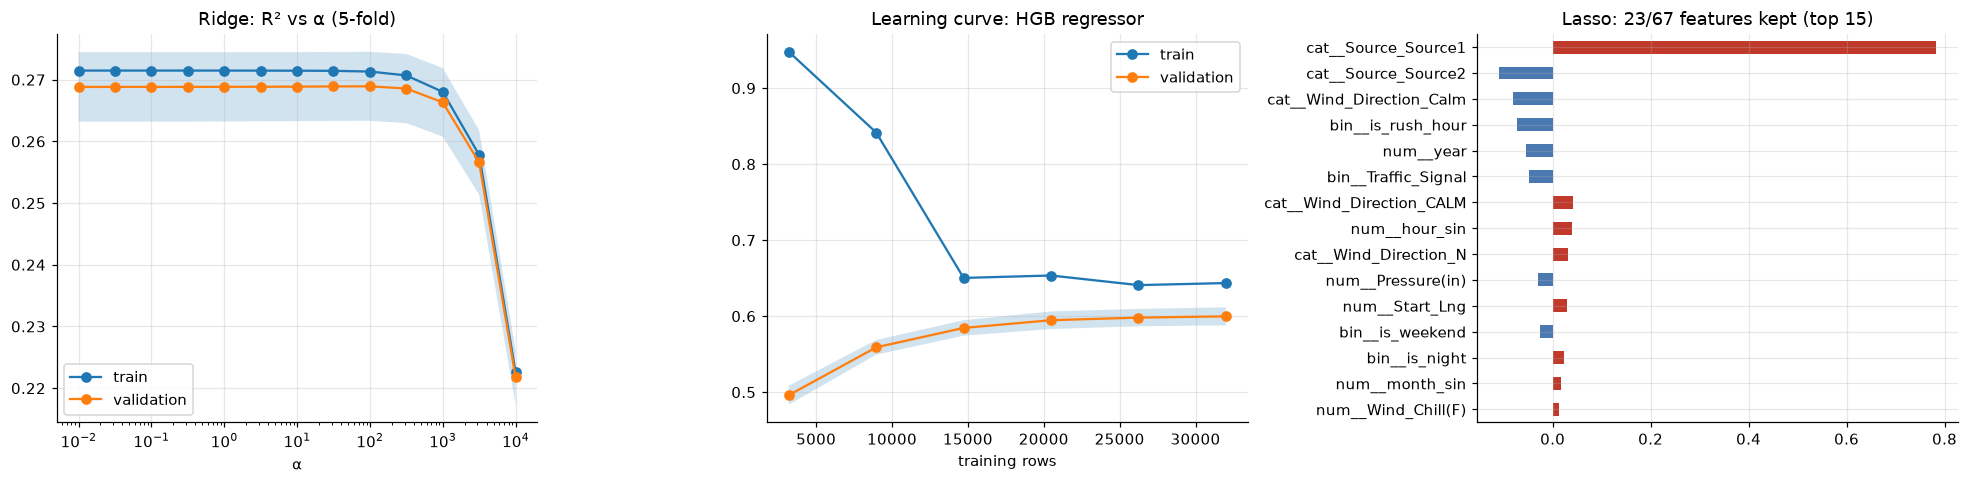

In [34]:
alphas = np.logspace(-2, 4, 13)
tr_s, va_s = validation_curve(make_pipe(Ridge(), NUM_R), Xr_cv, yr_cv, param_name="model__alpha", param_range=alphas, cv=kf, scoring="r2", n_jobs=1)
sizes, lc_tr, lc_va = learning_curve(make_pipe(HistGradientBoostingRegressor(max_iter=300, random_state=SEED), NUM_R), Xr_cv, yr_cv,
                                     train_sizes=np.linspace(0.1, 1.0, 6), cv=kf, scoring="r2", n_jobs=1)
lasso = fit_r["Lasso (L1, α=0.002)"]
lc = pd.Series(lasso.named_steps["model"].coef_, index=lasso.named_steps["pre"].get_feature_names_out())
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].semilogx(alphas, tr_s.mean(1), "o-", label="train"); ax[0].semilogx(alphas, va_s.mean(1), "o-", label="validation")
ax[0].fill_between(alphas, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), alpha=0.2); ax[0].set(title="Ridge: R² vs α (5-fold)", xlabel="α"); ax[0].legend()
ax[1].plot(sizes, lc_tr.mean(1), "o-", label="train"); ax[1].plot(sizes, lc_va.mean(1), "o-", label="validation")
ax[1].fill_between(sizes, lc_va.mean(1) - lc_va.std(1), lc_va.mean(1) + lc_va.std(1), alpha=0.2); ax[1].set(title="Learning curve: HGB regressor", xlabel="training rows"); ax[1].legend()
nz = lc[lc != 0]; nz = nz.reindex(nz.abs().sort_values().index).tail(15)
nz.plot.barh(ax=ax[2], color=[RED if v > 0 else BLUE for v in nz], title=f"Lasso: {int((lc != 0).sum())}/{len(lc)} features kept (top 15)")
plt.tight_layout(); plt.show()

### 10.2 Prediction intervals (quantile gradient boosting, 10th–90th percentile)

80% interval covers 79.0% of real delays (target 80%); median width 145 minutes


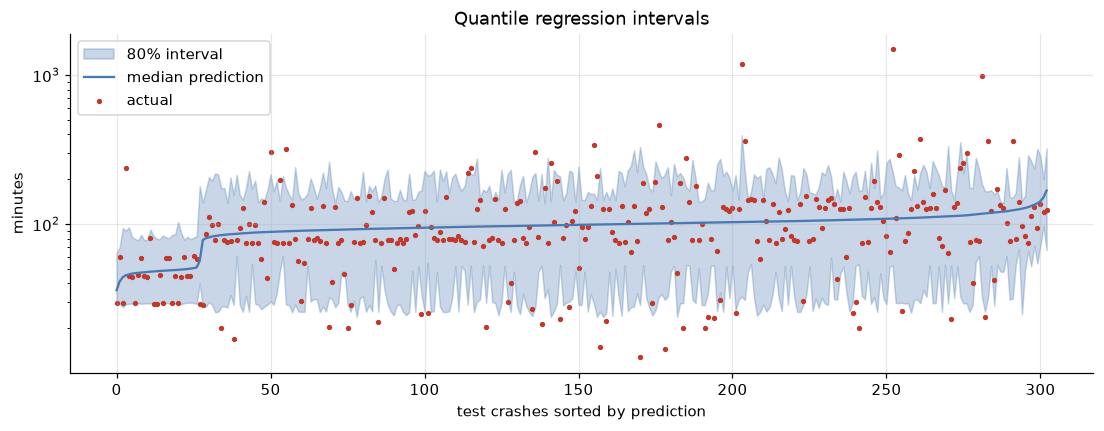

In [35]:
q = {a: make_pipe(HistGradientBoostingRegressor(loss="quantile", quantile=a, max_iter=300, random_state=SEED), NUM_R).fit(Xr_tr, yr_tr).predict(Xr_te) for a in (0.1, 0.5, 0.9)}
cover = ((yr_te >= q[0.1]) & (yr_te <= q[0.9])).mean()
print(f"80% interval covers {cover:.1%} of real delays (target 80%); median width {np.median(np.expm1(q[0.9]) - np.expm1(q[0.1])):.0f} minutes")
o = np.argsort(q[0.5])[:: max(1, len(q[0.5]) // 300)]
plt.figure(figsize=(12, 4)); plt.fill_between(range(len(o)), np.expm1(q[0.1][o]), np.expm1(q[0.9][o]), alpha=0.3, color=BLUE, label="80% interval")
plt.plot(np.expm1(q[0.5][o]), color=BLUE, label="median prediction"); plt.scatter(range(len(o)), np.expm1(yr_te.to_numpy()[o]), s=6, color=RED, label="actual")
plt.yscale("log"); plt.xlabel("test crashes sorted by prediction"); plt.ylabel("minutes"); plt.legend(); plt.title("Quantile regression intervals"); plt.show()
SUMMARY.append({"task": "Regression (delay)", "best model": best_r, "key metric": "R² log (future test)", "value": test_reg.loc[best_r, "R2_log"],
                "baseline": test_reg.loc["Dummy (mean)", "R2_log"], "other": f"MAE {test_reg.loc[best_r, 'MAE_min']:.1f} min vs {test_reg.loc['Dummy (mean)', 'MAE_min']:.1f}; 80% PI coverage {cover:.1%}"})

## 11. Time series — monthly US crash counts
Built from the full 10% national sample (772k rows) × 10 to represent all recorded crashes. Mar 2016 – Feb 2023 (84 complete months).

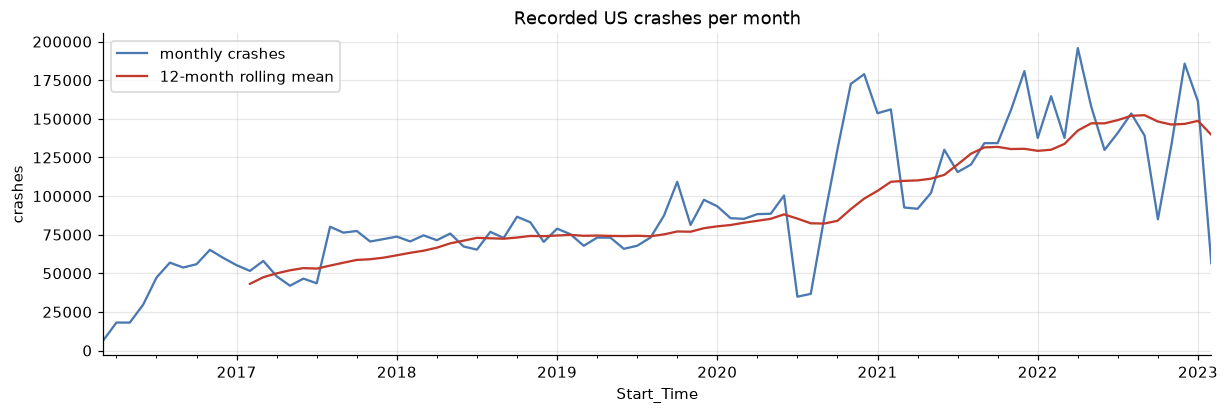

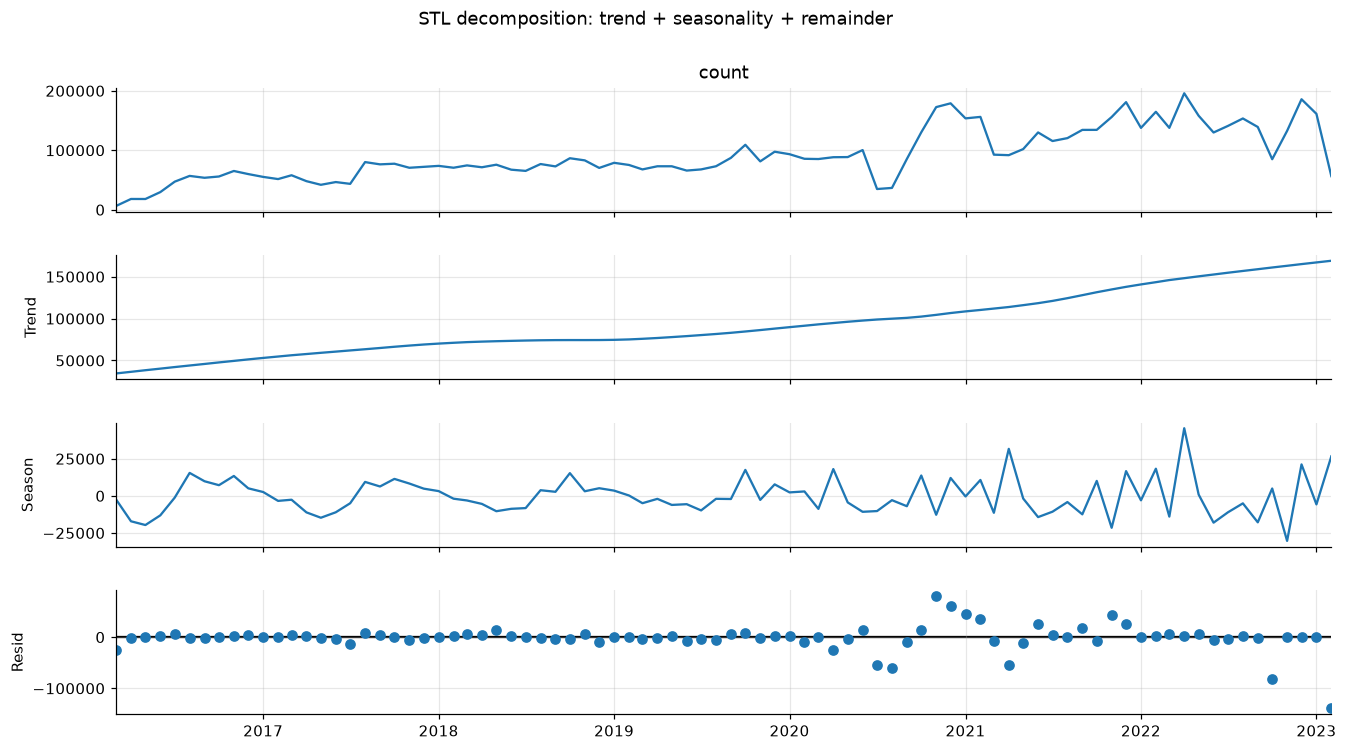

ADF test on level           : stat   -0.93, p-value 0.7774 -> NON-stationary
ADF test on first difference: stat   -4.82, p-value 0.0000 -> stationary


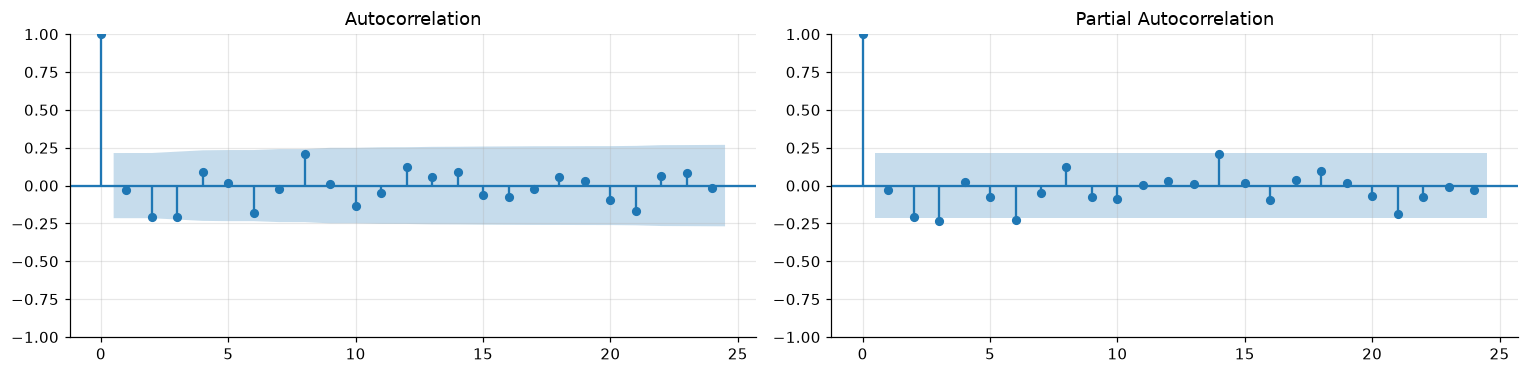

In [36]:
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
t_all = pd.to_datetime(raw_full.Start_Time.astype(str).str[:19], errors="coerce")
y_ts = (t_all.dt.to_period("M").value_counts().sort_index().loc["2016-03":"2023-02"] * 10).to_timestamp().asfreq("MS").astype(float)
fig, ax = plt.subplots(figsize=(13, 3.8))
y_ts.plot(ax=ax, color=BLUE, label="monthly crashes"); y_ts.rolling(12).mean().plot(ax=ax, color=RED, label="12-month rolling mean")
ax.set(title="Recorded US crashes per month", ylabel="crashes"); ax.legend(); plt.show()
stl = STL(y_ts, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(13, 7); fig.suptitle("STL decomposition: trend + seasonality + remainder", y=1.01); plt.show()
for name, s in [("level", y_ts), ("first difference", y_ts.diff().dropna())]:
    adf = adfuller(s); print(f"ADF test on {name:16s}: stat {adf[0]:7.2f}, p-value {adf[1]:.4f} -> {'stationary' if adf[1] < 0.05 else 'NON-stationary'}")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(y_ts.diff().dropna(), lags=24, ax=ax[0]); plot_pacf(y_ts.diff().dropna(), lags=24, ax=ax[1], method="ywm"); plt.tight_layout(); plt.show()

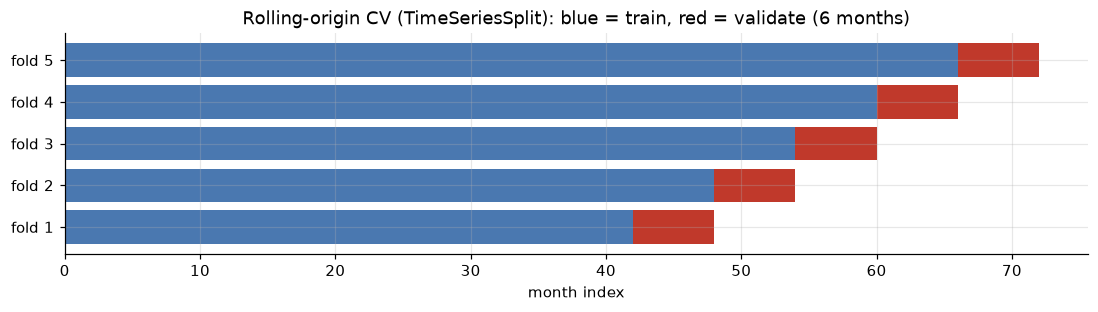

/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  start_params = self.start_params


/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  start_params = self.start_params


,MAE,RMSE,MAPE_%
Naive (last value),"45,411 ± 37,563","49,933 ± 37,183",41.8 ± 22.7
Seasonal naive,"29,453 ± 16,368","35,866 ± 19,613",27.8 ± 14.5
Moving average (3),"43,676 ± 28,337","48,506 ± 28,006",42.1 ± 19.1
Holt-Winters (damped),"41,791 ± 35,495","46,036 ± 35,819",39.9 ± 24.0
"SARIMA(1,1,1)(0,1,1)12","31,437 ± 23,881","36,757 ± 24,502",32.9 ± 20.4
Gradient boosting on lags,"32,091 ± 20,277","36,550 ± 20,674",34.1 ± 19.9


In [37]:
H = 12
train_ts, test_ts = y_ts[:-H], y_ts[-H:]
LAGS = [1, 2, 3, 6, 12]
def f_naive(s, h): return np.repeat(s.iloc[-1], h)
def f_snaive(s, h): return s.iloc[-12:].to_numpy()[:h]
def f_ma(s, h): return np.repeat(s.iloc[-3:].mean(), h)
def f_hw(s, h): return ExponentialSmoothing(s, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit().forecast(h).to_numpy()
def f_sarima(s, h): return SARIMAX(s, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h).to_numpy()
def f_gbm(s, h):
    v, mo = list(s.to_numpy(float)), list(s.index.month)
    X = [[v[t - l] for l in LAGS] + [np.sin(2 * np.pi * mo[t] / 12), np.cos(2 * np.pi * mo[t] / 12)] for t in range(12, len(v))]
    m = GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.05, random_state=SEED).fit(X, v[12:])
    out = []
    for i in range(h):   # recursive multi-step: feed predictions back as lags
        mon = (s.index[-1] + pd.DateOffset(months=i + 1)).month
        out.append(m.predict([[v[-l] for l in LAGS] + [np.sin(2 * np.pi * mon / 12), np.cos(2 * np.pi * mon / 12)]])[0]); v.append(out[-1])
    return np.array(out)
FC = {"Naive (last value)": f_naive, "Seasonal naive": f_snaive, "Moving average (3)": f_ma, "Holt-Winters (damped)": f_hw,
      "SARIMA(1,1,1)(0,1,1)12": f_sarima, "Gradient boosting on lags": f_gbm}
def fc_metrics(y, p): return {"MAE": M.mean_absolute_error(y, p), "RMSE": M.root_mean_squared_error(y, p), "MAPE_%": 100 * M.mean_absolute_percentage_error(y, p)}

tscv = TimeSeriesSplit(n_splits=5, test_size=6)
fig, ax = plt.subplots(figsize=(12, 2.6))
for i, (a, b) in enumerate(tscv.split(train_ts)):
    ax.barh(i, len(a), color=BLUE); ax.barh(i, len(b), left=len(a), color=RED)
ax.set(title="Rolling-origin CV (TimeSeriesSplit): blue = train, red = validate (6 months)", xlabel="month index", yticks=range(5), yticklabels=[f"fold {i + 1}" for i in range(5)]); plt.show()
cv_ts = {n: pd.DataFrame([fc_metrics(train_ts.iloc[b], f(train_ts.iloc[a], len(b))) for a, b in tscv.split(train_ts)]).agg(["mean", "std"]) for n, f in FC.items()}
display(pd.DataFrame({n: {k: f"{d.loc['mean', k]:,.0f} ± {d.loc['std', k]:,.0f}" if k != "MAPE_%" else f"{d.loc['mean', k]:.1f} ± {d.loc['std', k]:.1f}" for k in d} for n, d in cv_ts.items()}).T)

/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,MAE,RMSE,MAPE_%
Naive (last value),"33,715.8","44,578.6",36.0
Seasonal naive,"39,830.8","52,468.5",37.4
Moving average (3),"31,342.5","42,662.7",33.8
Holt-Winters (damped),"30,244.8","46,114.3",34.4
"SARIMA(1,1,1)(0,1,1)12","36,596.6","50,535.9",38.6
Gradient boosting on lags,"35,164.0","47,011.5",34.9


/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/smohanty13/Downloads/Temp/878_proj/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


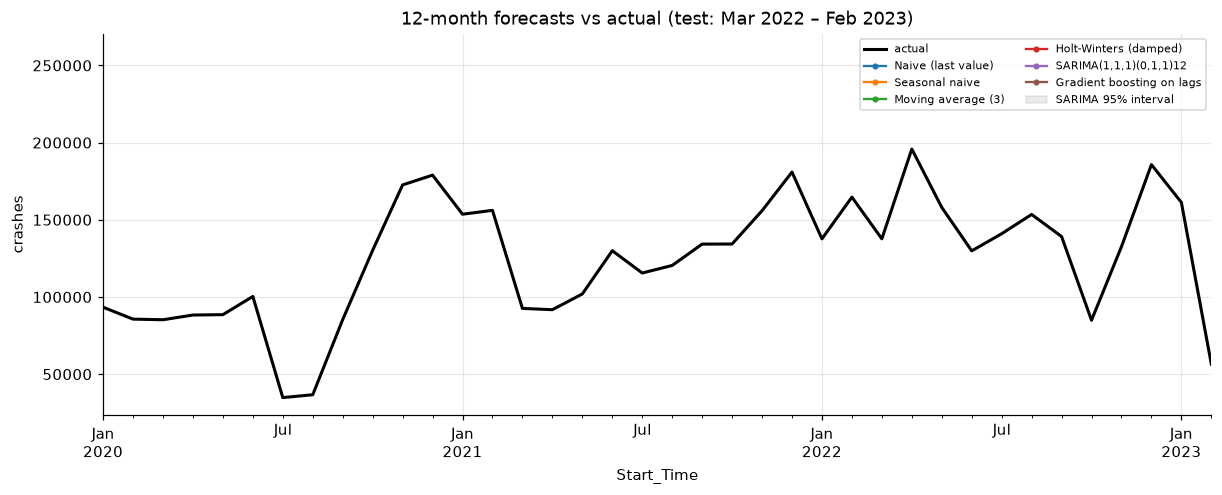

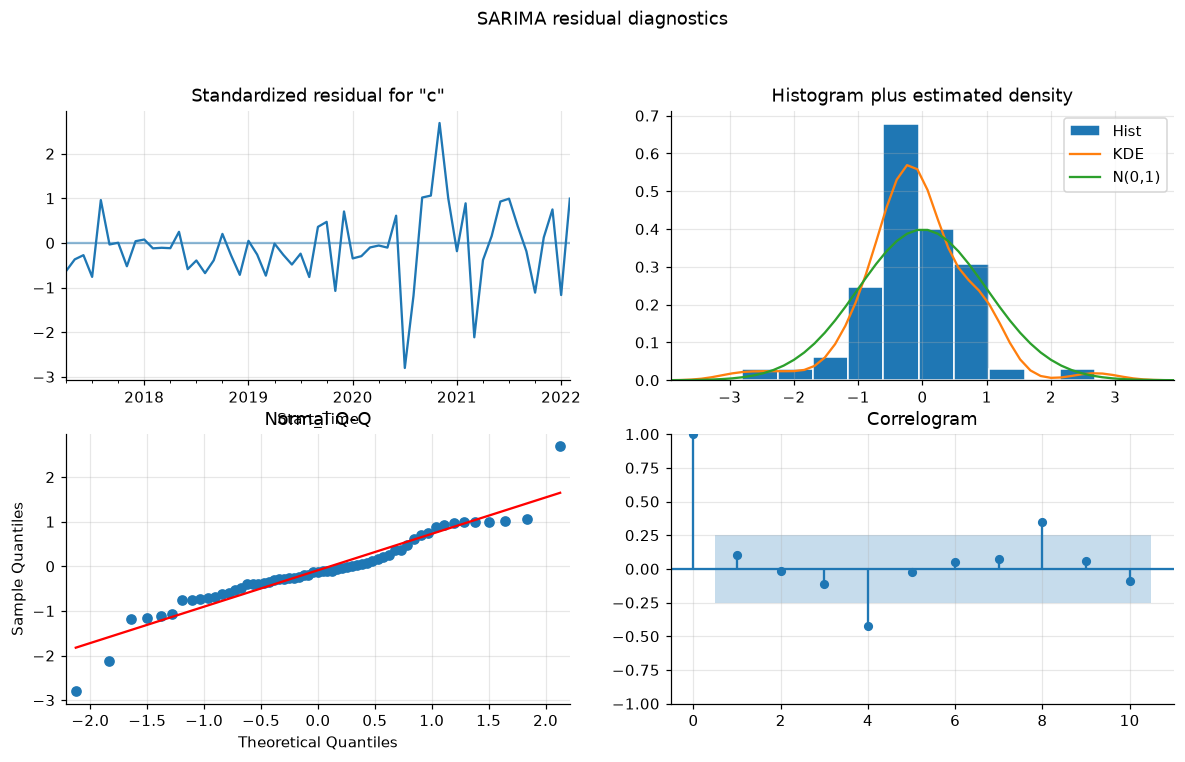

In [38]:
fc = {n: f(train_ts, H) for n, f in FC.items()}
test_ts_tbl = pd.DataFrame({n: fc_metrics(test_ts, p) for n, p in fc.items()}).T
display(test_ts_tbl.round(1).style.highlight_min(color="#cfe0f5").format("{:,.1f}"))
sar = SARIMAX(train_ts, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
ci = sar.get_forecast(H).conf_int()
fig, ax = plt.subplots(figsize=(13, 4.5))
y_ts["2020":].plot(ax=ax, color="k", lw=2, label="actual")
for n, p in fc.items():
    ax.plot(test_ts.index, p, marker="o", ms=3, label=n)
ax.fill_between(test_ts.index, ci.iloc[:, 0], ci.iloc[:, 1], color=GREY, alpha=0.2, label="SARIMA 95% interval")
ax.axvline(test_ts.index[0], ls="--", color=GREY); ax.set(title="12-month forecasts vs actual (test: Mar 2022 – Feb 2023)", ylabel="crashes"); ax.legend(fontsize=7, ncol=2); plt.show()
fig = sar.plot_diagnostics(figsize=(13, 7)); fig.suptitle("SARIMA residual diagnostics", y=1.01); plt.show()
best_ts = test_ts_tbl.MAE.idxmin()
SUMMARY.append({"task": "Time series (monthly count)", "best model": best_ts, "key metric": "MAE (12-month test)", "value": test_ts_tbl.loc[best_ts, "MAE"],
                "baseline": test_ts_tbl.loc["Seasonal naive", "MAE"], "other": f"MAPE {test_ts_tbl.loc[best_ts, 'MAPE_%']:.1f}% (seasonal naive {test_ts_tbl.loc['Seasonal naive', 'MAPE_%']:.1f}%)"})

## 12. Clustering — what types of crashes are there?
Features: time of day, light, weekend, weather, road features, severity and delay. Imputed, winsorized and **standardized** (essential: k-means uses Euclidean distance). 6,000 crashes sampled.

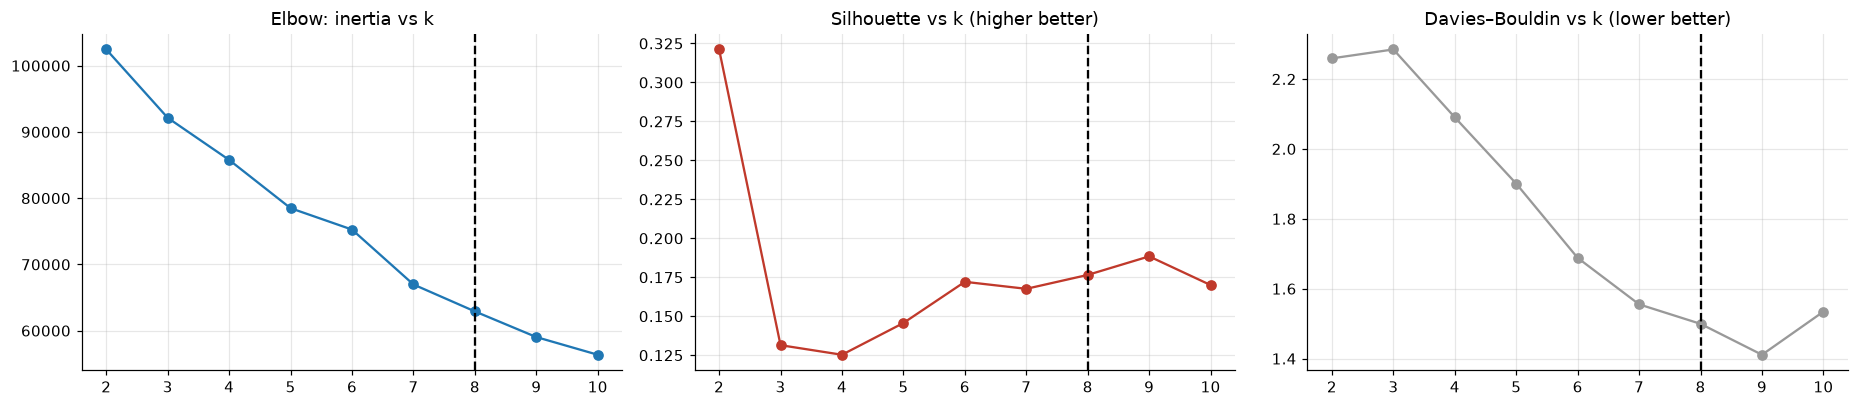

chosen k = 8


In [39]:
CL_FEATS = ["hour_sin", "hour_cos", "is_night", "is_weekend", "Temperature(F)", "Visibility(mi)", "Precipitation(in)", "Wind_Speed(mph)",
            "Junction", "Traffic_Signal", "Crossing", "Stop", "log_duration", "Severity"]
wx = pd.get_dummies(df.weather_group, prefix="wx").astype(int)[["wx_rain", "wx_snow", "wx_fog", "wx_clear", "wx_cloudy"]]
Craw = pd.concat([df[CL_FEATS], wx], axis=1).sample(6000, random_state=SEED)
Craw = Craw.fillna(Craw.median())
Zc = StandardScaler().fit_transform(Clipper().fit_transform(Craw))
ks = range(2, 11)
km_fits = {k: KMeans(k, n_init=10, random_state=SEED).fit(Zc) for k in ks}
el = pd.DataFrame({"inertia": [km_fits[k].inertia_ for k in ks], "silhouette": [M.silhouette_score(Zc, km_fits[k].labels_) for k in ks],
                   "davies_bouldin": [M.davies_bouldin_score(Zc, km_fits[k].labels_) for k in ks]}, index=ks)
K_BEST = int(el.loc[3:8, "silhouette"].idxmax())
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
el.inertia.plot(ax=ax[0], marker="o", title="Elbow: inertia vs k"); el.silhouette.plot(ax=ax[1], marker="o", color=RED, title="Silhouette vs k (higher better)")
el.davies_bouldin.plot(ax=ax[2], marker="o", color=GREY, title="Davies–Bouldin vs k (lower better)")
for a in ax: a.axvline(K_BEST, ls="--", color="k")
plt.tight_layout(); plt.show(); print("chosen k =", K_BEST)

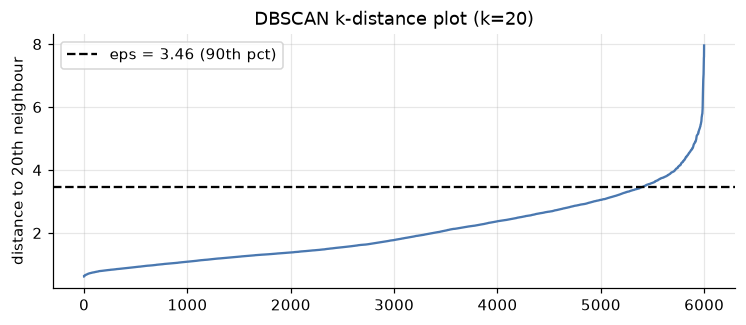

,clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
K-means,8.0,0.000,0.177,1.499,695.248
Mini-batch k-means,8.0,0.000,0.152,1.765,590.125
Gaussian mixture,8.0,0.000,0.134,2.224,560.577
Agglomerative (Ward),8.0,0.000,0.183,1.520,658.096
BIRCH,8.0,0.000,0.174,1.539,587.551
DBSCAN,6.0,3.033,0.245,1.269,500.351


Agreement with k-means (adjusted Rand index): {'Mini-batch k-means': 0.596, 'Gaussian mixture': 0.712, 'Agglomerative (Ward)': 0.557, 'BIRCH': 0.303, 'DBSCAN': 0.198}


In [40]:
knn_d = np.sort(NearestNeighbors(n_neighbors=20).fit(Zc).kneighbors(Zc)[0][:, -1])
EPS = float(np.quantile(knn_d, 0.90))
plt.figure(figsize=(8, 3)); plt.plot(knn_d, color=BLUE); plt.axhline(EPS, ls="--", color="k", label=f"eps = {EPS:.2f} (90th pct)")
plt.title("DBSCAN k-distance plot (k=20)"); plt.ylabel("distance to 20th neighbour"); plt.legend(); plt.show()
ALGOS = {"K-means": KMeans(K_BEST, n_init=10, random_state=SEED), "Mini-batch k-means": MiniBatchKMeans(K_BEST, n_init=10, random_state=SEED),
         "Gaussian mixture": GaussianMixture(K_BEST, covariance_type="full", random_state=SEED), "Agglomerative (Ward)": AgglomerativeClustering(K_BEST),
         "BIRCH": Birch(n_clusters=K_BEST), "DBSCAN": DBSCAN(eps=EPS, min_samples=20)}
labels, rows = {}, {}
for n, a in ALGOS.items():
    lab = a.fit_predict(Zc); labels[n] = lab; keep = lab != -1
    ok = len(set(lab[keep])) > 1
    rows[n] = {"clusters": len(set(lab[keep])), "noise_%": 100 * (~keep).mean(),
               "silhouette": M.silhouette_score(Zc[keep], lab[keep]) if ok else np.nan,
               "davies_bouldin": M.davies_bouldin_score(Zc[keep], lab[keep]) if ok else np.nan,
               "calinski_harabasz": M.calinski_harabasz_score(Zc[keep], lab[keep]) if ok else np.nan}
cl_tbl = pd.DataFrame(rows).T
display(cl_tbl.round(3))
print("Agreement with k-means (adjusted Rand index):", {n: round(M.adjusted_rand_score(labels["K-means"], l), 3) for n, l in labels.items() if n != "K-means"})

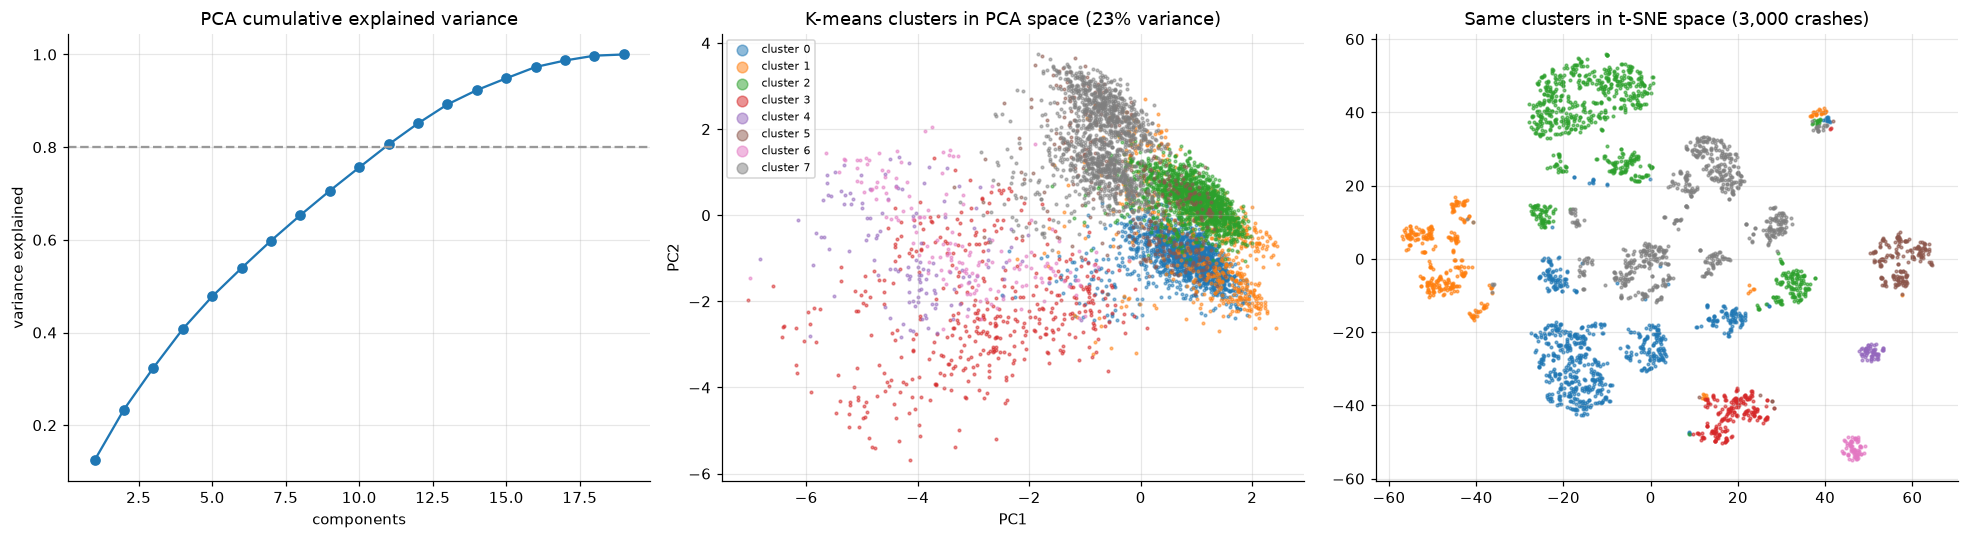

In [41]:
pca = PCA(random_state=SEED).fit(Zc); P2 = pca.transform(Zc)[:, :2]
ts_idx = rng.choice(len(Zc), 3000, replace=False)
T2 = TSNE(2, perplexity=40, random_state=SEED, init="pca").fit_transform(Zc[ts_idx])
lab = labels["K-means"]; cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), "o-"); ax[0].axhline(0.8, ls="--", color=GREY)
ax[0].set(title="PCA cumulative explained variance", xlabel="components", ylabel="variance explained")
for c in range(K_BEST):
    ax[1].scatter(P2[lab == c, 0], P2[lab == c, 1], s=3, alpha=0.5, color=cmap(c), label=f"cluster {c}")
    ax[2].scatter(T2[lab[ts_idx] == c, 0], T2[lab[ts_idx] == c, 1], s=3, alpha=0.6, color=cmap(c))
ax[1].set(title=f"K-means clusters in PCA space ({pca.explained_variance_ratio_[:2].sum():.0%} variance)", xlabel="PC1", ylabel="PC2"); ax[1].legend(markerscale=4, fontsize=7)
ax[2].set(title="Same clusters in t-SNE space (3,000 crashes)"); plt.tight_layout(); plt.show()

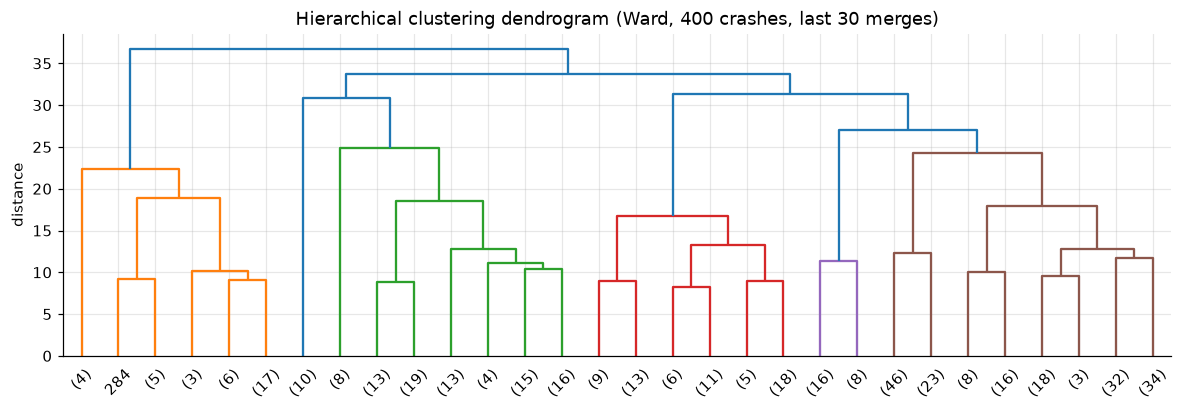

,size,severe_rate,median_delay_min,night_share,share,name
cluster,,,,,,
0,1425,0.243,60.000,0.005,0.238,high cloudy + low clear
1,630,0.051,60.042,0.227,0.105,high Crossing + high Traffic_Signal
2,1562,0.157,75.075,0.001,0.260,high clear + low cloudy
3,434,0.217,59.950,0.281,0.072,high rain + high Precipitation
4,126,0.190,79.258,0.437,0.021,high snow + low Visibility
5,367,0.248,78.000,0.376,0.061,high Junction + low Traffic_Signal
6,155,0.174,76.833,0.400,0.026,high fog + low Visibility
7,1301,0.210,77.950,1.000,0.217,high is_night + high hour_cos


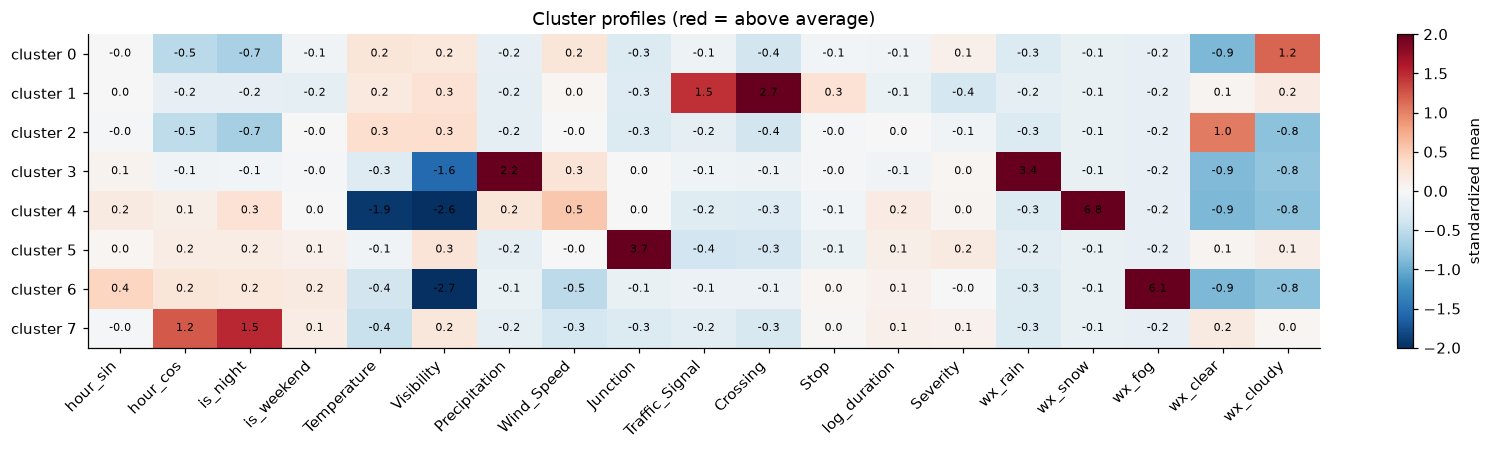

In [42]:
from scipy.cluster.hierarchy import linkage, dendrogram
plt.figure(figsize=(13, 3.8)); dendrogram(linkage(Zc[rng.choice(len(Zc), 400, replace=False)], "ward"), truncate_mode="lastp", p=30, color_threshold=None)
plt.title("Hierarchical clustering dendrogram (Ward, 400 crashes, last 30 merges)"); plt.ylabel("distance"); plt.show()
prof_z = pd.DataFrame(Zc, columns=Craw.columns).groupby(lab).mean()
prof = Craw.assign(cluster=lab).groupby("cluster").agg(size=("Severity", "size"), severe_rate=("Severity", lambda s: (s >= 3).mean()),
                                                         median_delay_min=("log_duration", lambda s: np.expm1(s.median())), night_share=("is_night", "mean"))
prof["share"] = prof["size"] / prof["size"].sum()
prof["name"] = [" + ".join(f"{'high' if prof_z.loc[c, f] > 0 else 'low'} {f.split('(')[0].replace('wx_', '')}" for f in prof_z.loc[c].abs().nlargest(2).index) for c in prof.index]
display(prof.round(3))
fig, ax = plt.subplots(figsize=(15, 4.2))
im = ax.imshow(prof_z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(prof_z.shape[1]), [c.split("(")[0] for c in prof_z.columns], rotation=45, ha="right"); ax.set_yticks(range(K_BEST), [f"cluster {c}" for c in prof_z.index])
for i in range(prof_z.shape[0]):
    for j in range(prof_z.shape[1]):
        ax.text(j, i, f"{prof_z.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="standardized mean"); ax.set_title("Cluster profiles (red = above average)"); ax.grid(False); plt.tight_layout(); plt.show()
SUMMARY.append({"task": "Clustering (crash types)", "best model": cl_tbl.silhouette.idxmax(), "key metric": "silhouette", "value": cl_tbl.silhouette.max(),
                "baseline": np.nan, "other": f"k = {K_BEST}; k-means silhouette {cl_tbl.loc['K-means', 'silhouette']:.3f}"})

### 12.1 Spatial clustering — crash hotspots in the Omaha metro (DBSCAN, haversine distance, 150 m radius)

26,192 Omaha-area crashes -> 179 hotspots holding 50.8% of crashes


,crashes,lat,lng,severe_rate,median_delay_min
hotspot,,,,,
8,627,41.2267,-95.9570,0.4848,59.1000
20,480,41.2240,-96.0429,0.8312,44.5500
44,419,41.2245,-95.9763,0.7709,44.3167
26,418,41.2238,-96.0044,0.8206,44.5083
43,328,41.2239,-96.0240,0.7470,44.3583
5,327,41.2585,-95.9555,0.1315,44.3500
33,257,41.2386,-95.9539,0.6265,44.6000
117,255,41.2634,-96.0762,0.6157,44.4667
22,210,41.2118,-95.9495,0.0429,44.5250


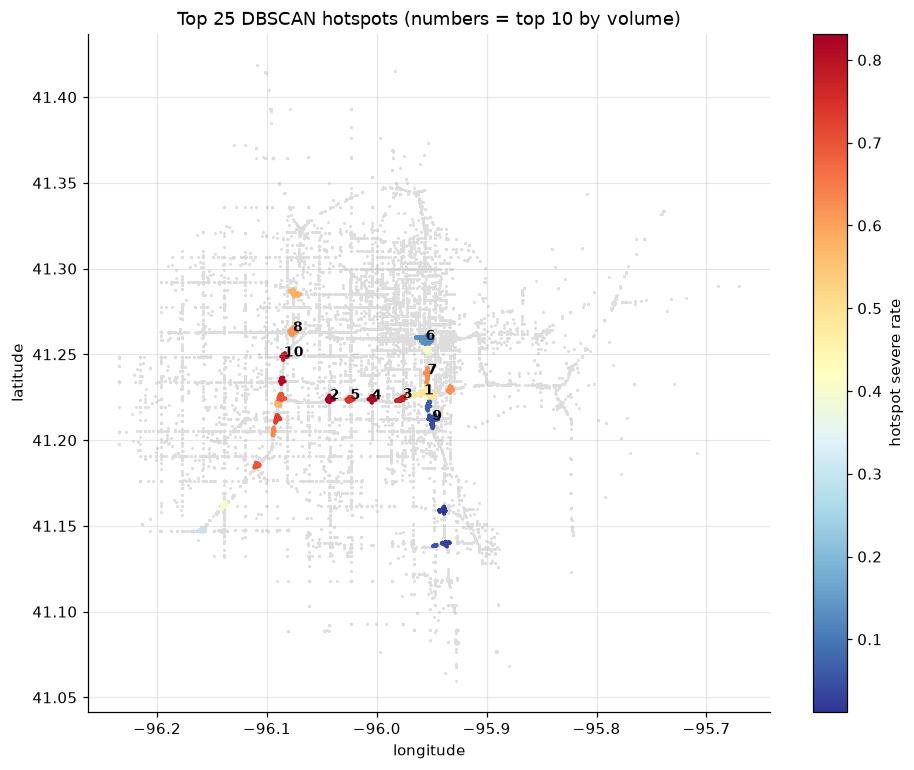

In [43]:
metro = pd.read_parquet("data/processed/metro.parquet")
om = clean(metro[metro.City.isin(["Omaha", "Bellevue", "Papillion", "La Vista", "Council Bluffs"])])
db = DBSCAN(eps=0.15 / 6371.0, min_samples=30, metric="haversine", algorithm="ball_tree").fit(np.radians(om[["Start_Lat", "Start_Lng"]]))
om = om.assign(hotspot=db.labels_)
hs = (om[om.hotspot >= 0].groupby("hotspot").agg(crashes=("Severity", "size"), lat=("Start_Lat", "mean"), lng=("Start_Lng", "mean"),
                                                 severe_rate=("is_severe", "mean"), median_delay_min=("duration_min", "median"))
      .sort_values("crashes", ascending=False))
print(f"{len(om):,} Omaha-area crashes -> {len(hs)} hotspots holding {(om.hotspot >= 0).mean():.1%} of crashes")
display(hs.head(10).round(4))
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(om.Start_Lng, om.Start_Lat, s=1, color="#dddddd", label="crash (not in hotspot)")
big = hs.head(25).index
inh = om[om.hotspot.isin(big)]
sc = ax.scatter(inh.Start_Lng, inh.Start_Lat, s=3, c=inh.hotspot.map(hs.severe_rate), cmap="RdYlBu_r")
for r, (h, row) in enumerate(hs.head(10).iterrows()):
    ax.annotate(str(r + 1), (row.lng, row.lat), fontsize=9, weight="bold")
plt.colorbar(sc, label="hotspot severe rate"); ax.set(title="Top 25 DBSCAN hotspots (numbers = top 10 by volume)", xlabel="longitude", ylabel="latitude"); plt.show()

## 13. Final summary

In [44]:
display(pd.DataFrame(SUMMARY).set_index("task").round(3))
print("Classification test table:"); display(test_cls[["balanced_acc", "f1_macro", "roc_auc", "pr_auc", "log_loss"]].round(3))
print("Regression test table:"); display(test_reg.round(3))
print("Forecasting test table:"); display(test_ts_tbl.round(1))
print("Clustering table:"); display(cl_tbl.round(3))

,best model,key metric,value,baseline,other
task,,,,,
Classification (severe vs not),HGB tuned,ROC-AUC (future test),0.856,0.500,macro F1 0.730 @thr 0.28
Regression (delay),Gradient boosting (HGB),R² log (future test),0.112,-0.087,MAE 61.6 min vs 67.5; 80% PI coverage 79.0%
Time series (monthly count),Holt-Winters (damped),MAE (12-month test),30244.781,39830.833,MAPE 34.4% (seasonal naive 37.4%)
Clustering (crash types),DBSCAN,silhouette,0.245,NaN,k = 8; k-means silhouette 0.177


Classification test table:


,balanced_acc,f1_macro,roc_auc,pr_auc,log_loss
Dummy (majority class),0.500,0.485,0.500,0.058,0.807
Logistic regression,0.504,0.493,0.755,0.335,0.195
Gaussian naive Bayes,0.590,0.384,0.646,0.133,2.357
k-nearest neighbours (k=25),0.519,0.523,0.751,0.236,0.238
Decision tree,0.626,0.668,0.832,0.393,0.183
Random forest,0.606,0.652,0.838,0.430,0.165
Gradient boosting (HGB),0.632,0.683,0.854,0.469,0.156
Neural network (MLP),0.617,0.659,0.826,0.383,0.177


Regression test table:


,MAE_log,RMSE_log,R2_log,MAE_min,MedAE_min,RMSE_min
Dummy (mean),0.564,0.765,-0.087,67.508,38.576,195.060
Linear regression,0.501,0.708,0.069,63.336,30.373,188.056
"Ridge (L2, α=10)",0.501,0.708,0.069,63.337,30.376,188.054
"Lasso (L1, α=0.002)",0.504,0.710,0.064,63.598,30.793,187.733
k-nearest neighbours (k=25),0.535,0.738,-0.012,66.293,34.573,189.744
Decision tree,0.499,0.709,0.066,63.379,28.835,188.709
Random forest,0.488,0.696,0.099,61.974,28.184,188.040
Gradient boosting (HGB),0.484,0.691,0.112,61.564,28.306,187.206
Neural network (MLP),0.537,0.743,-0.027,65.574,31.099,191.718


Forecasting test table:


,MAE,RMSE,MAPE_%
Naive (last value),33715.8,44578.6,36.0
Seasonal naive,39830.8,52468.5,37.4
Moving average (3),31342.5,42662.7,33.8
Holt-Winters (damped),30244.8,46114.3,34.4
"SARIMA(1,1,1)(0,1,1)12",36596.6,50535.9,38.6
Gradient boosting on lags,35164.0,47011.5,34.9


Clustering table:


,clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
K-means,8.0,0.000,0.177,1.499,695.248
Mini-batch k-means,8.0,0.000,0.152,1.765,590.125
Gaussian mixture,8.0,0.000,0.134,2.224,560.577
Agglomerative (Ward),8.0,0.000,0.183,1.520,658.096
BIRCH,8.0,0.000,0.174,1.539,587.551
DBSCAN,6.0,3.033,0.245,1.269,500.351


**Takeaways**
- **Severity** is predictable well above chance from time, weather, road features, location and reporting source; gradient boosting is the strongest family, and tuning + a CV-chosen threshold improve the severe-class F1. The temporal test is clearly harder than a random split because severity labelling and coverage drift over time.
- **Delay duration** is only partly predictable (heavy-tailed, driven by unrecorded incident details); tree ensembles beat linear models, and quantile boosting gives calibrated 80% intervals.
- **Monthly volume** has strong trend/coverage shifts; classical seasonal models (Holt-Winters / SARIMA) are compared against naive baselines with rolling-origin CV.
- **Clustering** finds interpretable crash types (night, weather, intersection, long-delay groups); separation is modest (silhouette ≈ 0.1–0.25), typical for mixed tabular data.
- **Outliers** were investigated, not deleted: impossible sensor values set to missing, extremes winsorized inside the pipeline only.